# ***FINAL HACKATHON***

**Submitted by: Prathiba Reddy Namireddy**




Purpose of the model: To predict whether a loan applicant will default on their repayment (TARGET = 1) or successfully repay (TARGET = 0), using demographic, financial, and behavioural features drawn from the main application table

In [31]:
import pandas as pd

train = pd.read_csv('/content/train_x3.csv')
test = pd.read_csv('/content/test_x3 (1).csv')

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

print(f"\nTrain has {len(train.columns)} columns")
print(f"Test has {len(test.columns)} columns")

print(f"\nCurrent Train columns:\n{list(train.columns)}")
print(f"\nCurrent Test columns:\n{list(test.columns)}")

Train shape: (5859, 108)
Test shape: (1950, 82)

Train has 108 columns
Test has 82 columns

Current Train columns:
['ed', 'House / apartment', '0.00823', '-17048', '-1471', '-9633.0', '-578', '6.0', '1', '1.1', '0', '1.2', '0.1', '0.2', 'Drivers', '2.0', '2', '2.1', 'SATURDAY', '12', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', 'Business Entity Type 3', 'Unnamed: 27', '0.162230739097593', '0.8357765157975799', '0.0639', '0.0585', '0.9752', 'Unnamed: 33', 'Unnamed: 34', '0.0', '0.1034', '0.1667', 'Unnamed: 38', '0.0421', 'Unnamed: 40', '0.0513', 'Unnamed: 42', '0.0.1', '0.0651', '0.0607', '0.9752.1', 'Unnamed: 47', 'Unnamed: 48', '0.0.2', '0.1034.1', '0.1667.1', 'Unnamed: 52', '0.0431', 'Unnamed: 54', '0.0535', 'Unnamed: 56', '0.0.3', '0.0645', '0.0585.1', '0.9752.2', 'Unnamed: 61', 'Unnamed: 62', '0.0.4', '0.1034.2', '0.1667.2', 'Unnamed: 66', '0.0429', 'Unnamed: 68', '0.0523', 'Unnamed: 70', '0.0.5', 'Unnamed: 72', 'block of flats', '0.0404', 'Panel', 'No', '1.0', '0.0.6', '1.0.1', '0.0.

**ENVIRONMENT SETUP & LIBRARY IMPORTS**

Installing and importing all necessary libraries for:
- Data manipulation & visualization
- Machine Learning & Class Imbalance Handling
- Explainability (SHAP, LIME, DiCE)
- Fairness & Bias Auditing (Fairlearn)

 Explicitly included fairness and explainability libraries
from the start, ensuring RAI is baked into the pipeline, not an afterthought.



In [32]:

import warnings
warnings.filterwarnings('ignore')

# Core Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Feature Engineering
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Class Imbalance Handling
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Models
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression

# Evaluation Metrics
from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    classification_report, confusion_matrix, f1_score, precision_score, recall_score,
    accuracy_score
)

# Explainability - XAI
import shap

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
plt.style.use('seaborn-v0_8-whitegrid')

print("✅ All libraries imported successfully!")


✅ All libraries imported successfully!


**DATA LOADING WITH PROPER COLUMN NAMES**



In [33]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Define train columns (122 columns)
train_columns = [
    'SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH',
    'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL',
    'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL',
    'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY',
    'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION',
    'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY',
    'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1',
    'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG',
    'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG',
    'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG',
    'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE',
    'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE',
    'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMAX_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE',
    'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE',
    'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BEGINEXPLUATATION_MEDI', 'YEARS_BUILD_MEDI',
    'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMAX_MEDI', 'FLOORSMIN_MEDI',
    'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI',
    'NONLIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'TOTALAREA_MODE',
    'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE', 'OBS_30_CNT_SOCIAL_CIRCLE',
    'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
    'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_4',
    'FLAG_DOCUMENT_5', 'FLAG_DOCUMENT_6', 'FLAG_DOCUMENT_7', 'FLAG_DOCUMENT_8',
    'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_12',
    'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_15', 'FLAG_DOCUMENT_16',
    'FLAG_DOCUMENT_17', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
    'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY',
    'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
    'AMT_REQ_CREDIT_BUREAU_YEAR'
]

# Define test columns (121 columns - same as train but without TARGET)
test_columns = [col for col in train_columns if col != 'TARGET']

# Load train and test with correct headers (skip first row which has bad headers)
train = pd.read_csv('/content/train_x3.csv', skiprows=1, header=None, names=train_columns)
test = pd.read_csv('/content/test_x3 (1).csv', skiprows=1, header=None, names=test_columns)

# Verify
print("="*60)
print("DATA LOADED SUCCESSFULLY")
print("="*60)
print(f"\nTrain shape: {train.shape}")
print(f"Test shape: {test.shape}")

print(f"\nTrain columns (first 10): {list(train.columns[:10])}")
print(f"Test columns (first 10): {list(test.columns[:10])}")

print(f"\n{'='*60}")
print("TARGET Distribution (Train)")
print("="*60)
print(train['TARGET'].value_counts())
print(f"\nDefault Rate: {train['TARGET'].mean()*100:.2f}%")

print(f"\n{'='*60}")
print("Sample Data - Train (first 3 rows, first 8 columns)")
print("="*60)
print(train.iloc[:3, :8])

print(f"\n{'='*60}")
print("Sample Data - Test (first 3 rows, first 8 columns)")
print("="*60)
print(test.iloc[:3, :8])

DATA LOADED SUCCESSFULLY

Train shape: (5859, 122)
Test shape: (1950, 121)

Train columns (first 10): ['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']
Test columns (first 10): ['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

TARGET Distribution (Train)
TARGET
0    5400
1     459
Name: count, dtype: int64

Default Rate: 7.83%

Sample Data - Train (first 3 rows, first 8 columns)
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      296689       0         Cash loans           M            Y   
1      194778       0         Cash loans           F            N   
2      384983       0         Cash loans           F            Y   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  
0               N             0          180000.0  
1  

**DATA QUALITY ASSESSMENT & MISSING VALUE ANALYSIS**

In [34]:
print("\n📊 DATA TYPES OVERVIEW")
print("-"*50)
print(train.dtypes.value_counts())

# 2. Missing Values Analysis
print("\n📊 MISSING VALUES ANALYSIS - TRAIN")
print("-"*50)

missing_train = train.isnull().sum()
missing_train_pct = (train.isnull().sum() / len(train)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_train,
    'Missing %': missing_train_pct
}).sort_values('Missing %', ascending=False)

# Show columns with missing values
missing_cols = missing_df[missing_df['Missing Count'] > 0]
print(f"\nColumns with missing values: {len(missing_cols)} out of {len(train.columns)}")
print(f"\n{missing_cols.to_string()}")

# 3. Identify columns with >50% missing (candidates for dropping)
print("\n" + "="*70)
print("⚠️  COLUMNS WITH >50% MISSING VALUES (Candidates for Dropping)")
print("="*70)
high_missing = missing_df[missing_df['Missing %'] > 50]
print(f"\nNumber of columns with >50% missing: {len(high_missing)}")
if len(high_missing) > 0:
    print(f"\n{high_missing.to_string()}")

# 4. Identify columns with >40% missing
print("\n" + "="*70)
print("⚠️  COLUMNS WITH >40% MISSING VALUES")
print("="*70)
medium_missing = missing_df[(missing_df['Missing %'] > 40) & (missing_df['Missing %'] <= 50)]
print(f"\nNumber of columns with 40-50% missing: {len(medium_missing)}")
if len(medium_missing) > 0:
    print(f"\n{medium_missing.to_string()}")

# 5. Categorical vs Numerical columns
print("\n" + "="*70)
print("📊 COLUMN TYPE BREAKDOWN")
print("="*70)

categorical_cols = train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(f"\nCategorical columns: {len(categorical_cols)}")
print(categorical_cols)

print(f"\nNumerical columns: {len(numerical_cols)}")

# 6. Check for anomalies in DAYS_EMPLOYED (365243 is sentinel value)
print("\n" + "="*70)
print("🔍 ANOMALY CHECK: DAYS_EMPLOYED")
print("="*70)
print(f"\nDAYS_EMPLOYED value counts (top 10):")
print(train['DAYS_EMPLOYED'].value_counts().head(10))
print(f"\nMax value: {train['DAYS_EMPLOYED'].max()}")
print(f"Rows with 365243 (anomalous): {(train['DAYS_EMPLOYED'] == 365243).sum()}")


📊 DATA TYPES OVERVIEW
--------------------------------------------------
float64    85
int64      21
object     16
Name: count, dtype: int64

📊 MISSING VALUES ANALYSIS - TRAIN
--------------------------------------------------

Columns with missing values: 85 out of 122

                              Missing Count  Missing %
COMMONAREA_AVG                         4127  70.438641
COMMONAREA_MODE                        4127  70.438641
COMMONAREA_MEDI                        4127  70.438641
NONLIVINGAPARTMENTS_MEDI               4060  69.295102
NONLIVINGAPARTMENTS_MODE               4060  69.295102
NONLIVINGAPARTMENTS_AVG                4060  69.295102
LIVINGAPARTMENTS_AVG                   4003  68.322239
LIVINGAPARTMENTS_MODE                  4003  68.322239
LIVINGAPARTMENTS_MEDI                  4003  68.322239
FONDKAPREMONT_MODE                     4000  68.271036
FLOORSMIN_MODE                         3972  67.793139
FLOORSMIN_AVG                          3972  67.793139
FLOORSMIN_ME

**DATA CLEANING**

In [35]:

# Store original shapes
original_train_cols = train.shape[1]
original_test_cols = test.shape[1]

# --------------------------------------------------------------
# 1. Drop columns with >50% missing values
# --------------------------------------------------------------
print("\n📌 1. DROPPING COLUMNS WITH >50% MISSING VALUES")
print("-"*50)

# Identify columns with >50% missing in train
missing_pct = (train.isnull().sum() / len(train)) * 100
cols_to_drop = missing_pct[missing_pct > 50].index.tolist()

print(f"Columns to drop: {len(cols_to_drop)}")
print(cols_to_drop)

# Drop from both train and test
train = train.drop(columns=cols_to_drop)
test = test.drop(columns=[col for col in cols_to_drop if col in test.columns])

print(f"\n✅ Train: {original_train_cols} → {train.shape[1]} columns")
print(f"✅ Test: {original_test_cols} → {test.shape[1]} columns")

# --------------------------------------------------------------
# 2. Fix DAYS_EMPLOYED anomaly (365243 is sentinel for unemployed/pensioners)
# --------------------------------------------------------------
print("\n📌 2. FIXING DAYS_EMPLOYED ANOMALY")
print("-"*50)

anomaly_count_train = (train['DAYS_EMPLOYED'] == 365243).sum()
anomaly_count_test = (test['DAYS_EMPLOYED'] == 365243).sum()

print(f"Anomalous values (365243) in train: {anomaly_count_train}")
print(f"Anomalous values (365243) in test: {anomaly_count_test}")

# Create a flag for anomalous employment (could be useful feature)
train['DAYS_EMPLOYED_ANOMALY'] = (train['DAYS_EMPLOYED'] == 365243).astype(int)
test['DAYS_EMPLOYED_ANOMALY'] = (test['DAYS_EMPLOYED'] == 365243).astype(int)

# Replace 365243 with NaN
train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(365243, np.nan)
test['DAYS_EMPLOYED'] = test['DAYS_EMPLOYED'].replace(365243, np.nan)

print(f"\n✅ Created DAYS_EMPLOYED_ANOMALY flag")
print(f"✅ Replaced 365243 with NaN for imputation")

# --------------------------------------------------------------
# 3. Check remaining missing values
# --------------------------------------------------------------
print("\n📌 3. REMAINING MISSING VALUES AFTER CLEANING")
print("-"*50)

remaining_missing = train.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

print(f"\nColumns still with missing values: {len(remaining_missing)}")
print("\n" + remaining_missing.to_string())

# --------------------------------------------------------------
# 4. Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ CLEANING SUMMARY")
print("="*70)
print(f"\nTrain shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"\nColumns dropped: {len(cols_to_drop)}")
print(f"New feature added: DAYS_EMPLOYED_ANOMALY")
print(f"Remaining columns with missing values: {len(remaining_missing)}")


📌 1. DROPPING COLUMNS WITH >50% MISSING VALUES
--------------------------------------------------
Columns to drop: 44
['OWN_CAR_AGE', 'EXT_SOURCE_1', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'ELEVATORS_MODE', 'ENTRANCES_MODE', 'FLOORSMAX_MODE', 'FLOORSMIN_MODE', 'LANDAREA_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAREA_MODE', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAREA_MODE', 'APARTMENTS_MEDI', 'BASEMENTAREA_MEDI', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'ELEVATORS_MEDI', 'ENTRANCES_MEDI', 'FLOORSMAX_MEDI', 'FLOORSMIN_MEDI', 'LANDAREA_MEDI', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAREA_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAREA_MEDI', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']

✅ Train: 122 

**DROPPING REMAINING HIGH-MISSING COLUMNS (>40%)**

In [36]:


# Check current missing percentages
missing_pct = (train.isnull().sum() / len(train)) * 100
high_missing_cols = missing_pct[missing_pct > 40].index.tolist()

print(f"Columns with >40% missing: {high_missing_cols}")

# Drop these columns
train = train.drop(columns=high_missing_cols)
test = test.drop(columns=[col for col in high_missing_cols if col in test.columns])

print(f"\n✅ Dropped {len(high_missing_cols)} more columns")
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

# --------------------------------------------------------------
# 2. Separate categorical and numerical columns
# --------------------------------------------------------------
print("\n📌 2. IDENTIFYING COLUMN TYPES")
print("-"*50)

# Exclude SK_ID_CURR and TARGET from processing
id_col = 'SK_ID_CURR'
target_col = 'TARGET'

categorical_cols = train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_cols = [col for col in numerical_cols if col not in [id_col, target_col]]

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols}")
print(f"\nNumerical columns ({len(numerical_cols)}): {len(numerical_cols)} columns")

# --------------------------------------------------------------
# 3. Impute CATEGORICAL columns with mode or 'Unknown'
# --------------------------------------------------------------
print("\n📌 3. IMPUTING CATEGORICAL COLUMNS")
print("-"*50)

for col in categorical_cols:
    missing_train = train[col].isnull().sum()
    missing_test = test[col].isnull().sum() if col in test.columns else 0

    if missing_train > 0 or missing_test > 0:
        # Use mode for low missing, 'Unknown' for high missing
        if missing_train / len(train) > 0.2:
            fill_value = 'Unknown'
        else:
            fill_value = train[col].mode()[0]

        train[col] = train[col].fillna(fill_value)
        if col in test.columns:
            test[col] = test[col].fillna(fill_value)

        print(f"✅ {col}: filled {missing_train} (train), {missing_test} (test) with '{fill_value}'")

# --------------------------------------------------------------
# 4. Impute NUMERICAL columns with median
# --------------------------------------------------------------
print("\n📌 4. IMPUTING NUMERICAL COLUMNS")
print("-"*50)

imputed_count = 0
for col in numerical_cols:
    missing_train = train[col].isnull().sum()
    missing_test = test[col].isnull().sum() if col in test.columns else 0

    if missing_train > 0 or missing_test > 0:
        median_val = train[col].median()

        train[col] = train[col].fillna(median_val)
        if col in test.columns:
            test[col] = test[col].fillna(median_val)

        imputed_count += 1
        if missing_train > 100:  # Only print significant ones
            print(f"✅ {col}: filled {missing_train} (train), {missing_test} (test) with median={median_val:.2f}")

print(f"\n✅ Total numerical columns imputed: {imputed_count}")

# --------------------------------------------------------------
# 5. Verify no missing values remain
# --------------------------------------------------------------
print("\n📌 5. VERIFICATION - MISSING VALUES CHECK")
print("-"*50)

train_missing = train.isnull().sum().sum()
test_missing = test.isnull().sum().sum()

print(f"Train missing values: {train_missing}")
print(f"Test missing values: {test_missing}")

if train_missing == 0 and test_missing == 0:
    print("\n✅ All missing values handled successfully!")

# --------------------------------------------------------------
# 6. Final Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ DATA CLEANING COMPLETE - SUMMARY")
print("="*70)
print(f"\nFinal Train shape: {train.shape}")
print(f"Final Test shape: {test.shape}")
print(f"\nCategorical columns: {len(categorical_cols)}")
print(f"Numerical columns: {len(numerical_cols)}")
print(f"\nColumns in train: {list(train.columns)}")

Columns with >40% missing: ['YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BEGINEXPLUATATION_MEDI', 'TOTALAREA_MODE', 'EMERGENCYSTATE_MODE']

✅ Dropped 5 more columns
Train shape: (5859, 74)
Test shape: (1950, 73)

📌 2. IDENTIFYING COLUMN TYPES
--------------------------------------------------
Categorical columns (12): ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE']

Numerical columns (60): 60 columns

📌 3. IMPUTING CATEGORICAL COLUMNS
--------------------------------------------------
✅ NAME_TYPE_SUITE: filled 29 (train), 2 (test) with 'Unaccompanied'
✅ OCCUPATION_TYPE: filled 1874 (train), 614 (test) with 'Unknown'

📌 4. IMPUTING NUMERICAL COLUMNS
--------------------------------------------------
✅ DAYS_EMPLOYED: filled 1070 (train), 350 (test) with median=-1658.

**DATA VALIDATION & ERROR CHECK**

In [37]:
# --------------------------------------------------------------
# 1. Check for commas, special characters in data
# --------------------------------------------------------------
print("\n📌 1. CHECKING FOR COMMAS & SPECIAL CHARACTERS")
print("-"*50)

def check_special_chars(df, df_name):
    issues = []
    for col in df.columns:
        if df[col].dtype == 'object':
            # Check for commas
            comma_count = df[col].astype(str).str.contains(',', na=False).sum()
            if comma_count > 0:
                issues.append(f"⚠️  {col}: {comma_count} values contain commas")

            # Check for leading/trailing spaces
            space_count = df[col].astype(str).str.contains(r'^\s|\s$', na=False, regex=True).sum()
            if space_count > 0:
                issues.append(f"⚠️  {col}: {space_count} values have leading/trailing spaces")

            # Check for special characters (excluding normal punctuation)
            special_count = df[col].astype(str).str.contains(r'[#$%&*@!]', na=False, regex=True).sum()
            if special_count > 0:
                issues.append(f"⚠️  {col}: {special_count} values contain special characters")

    if issues:
        print(f"\n{df_name} issues found:")
        for issue in issues:
            print(issue)
    else:
        print(f"✅ {df_name}: No special character issues found")

    return issues

train_issues = check_special_chars(train, "TRAIN")
test_issues = check_special_chars(test, "TEST")

# --------------------------------------------------------------
# 2. Check for mixed types in columns
# --------------------------------------------------------------
print("\n📌 2. CHECKING FOR MIXED DATA TYPES")
print("-"*50)

def check_mixed_types(df, df_name):
    mixed = []
    for col in df.columns:
        types = df[col].apply(type).unique()
        if len(types) > 1:
            mixed.append(f"⚠️  {col}: mixed types {types}")

    if mixed:
        print(f"\n{df_name} mixed types:")
        for m in mixed:
            print(m)
    else:
        print(f"✅ {df_name}: No mixed types found")

check_mixed_types(train, "TRAIN")
check_mixed_types(test, "TEST")

# --------------------------------------------------------------
# 3. Check numerical columns stored as strings
# --------------------------------------------------------------
print("\n📌 3. CHECKING FOR NUMBERS STORED AS STRINGS")
print("-"*50)

object_cols = train.select_dtypes(include=['object']).columns.tolist()

for col in object_cols:
    # Sample non-null values
    sample = train[col].dropna().head(10).tolist()

    # Check if values look numeric
    numeric_looking = 0
    for val in sample:
        try:
            float(str(val).replace(',', ''))
            numeric_looking += 1
        except:
            pass

    if numeric_looking > 5:  # More than half look numeric
        print(f"⚠️  {col}: might be numeric (sample: {sample[:3]})")
    else:
        print(f"✅ {col}: correctly categorical (sample: {sample[:3]})")

# --------------------------------------------------------------
# 4. Check for duplicate rows
# --------------------------------------------------------------
print("\n📌 4. CHECKING FOR DUPLICATE ROWS")
print("-"*50)

train_dupes = train.duplicated().sum()
test_dupes = test.duplicated().sum()
print(f"Train duplicate rows: {train_dupes}")
print(f"Test duplicate rows: {test_dupes}")

# Check duplicate SK_ID_CURR
train_id_dupes = train['SK_ID_CURR'].duplicated().sum()
test_id_dupes = test['SK_ID_CURR'].duplicated().sum()
print(f"\nTrain duplicate SK_ID_CURR: {train_id_dupes}")
print(f"Test duplicate SK_ID_CURR: {test_id_dupes}")

# --------------------------------------------------------------
# 5. Check categorical columns for inconsistencies
# --------------------------------------------------------------
print("\n📌 5. CHECKING CATEGORICAL VALUES FOR INCONSISTENCIES")
print("-"*50)

categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    unique_train = set(train[col].dropna().unique())
    unique_test = set(test[col].dropna().unique()) if col in test.columns else set()

    # Check for values in test but not in train
    test_only = unique_test - unique_train
    if test_only:
        print(f"⚠️  {col}: test has values not in train: {test_only}")

    # Check for 'XNA', 'Unknown', empty strings
    suspicious = {'XNA', 'Unknown', '', ' ', 'NA', 'N/A', 'null', 'None'}
    found_suspicious = unique_train.intersection(suspicious)
    if found_suspicious:
        print(f"⚠️  {col}: contains suspicious values: {found_suspicious}")

# --------------------------------------------------------------
# 6. Detailed look at each categorical column
# --------------------------------------------------------------
print("\n📌 6. CATEGORICAL COLUMN VALUE COUNTS")
print("-"*50)

for col in categorical_cols:
    print(f"\n{col}:")
    print(train[col].value_counts())

# --------------------------------------------------------------
# 7. Check for negative values where they shouldn't exist
# --------------------------------------------------------------
print("\n\n📌 7. CHECKING FOR UNEXPECTED NEGATIVE VALUES")
print("-"*50)

should_be_positive = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE',
                      'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'REGION_POPULATION_RELATIVE']

for col in should_be_positive:
    if col in train.columns:
        neg_count = (train[col] < 0).sum()
        if neg_count > 0:
            print(f"⚠️  {col}: {neg_count} negative values")
        else:
            print(f"✅ {col}: No negative values")

# --------------------------------------------------------------
# 8. Check DAYS columns (should be negative or zero)
# --------------------------------------------------------------
print("\n📌 8. CHECKING DAYS COLUMNS")
print("-"*50)

days_cols = ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']

for col in days_cols:
    if col in train.columns:
        min_val = train[col].min()
        max_val = train[col].max()
        positive_count = (train[col] > 0).sum()
        print(f"{col}: min={min_val}, max={max_val}, positive_values={positive_count}")

# --------------------------------------------------------------
# 9. Check for outliers in key financial columns
# --------------------------------------------------------------
print("\n📌 9. OUTLIER CHECK - KEY FINANCIAL COLUMNS")
print("-"*50)

financial_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

for col in financial_cols:
    if col in train.columns:
        Q1 = train[col].quantile(0.25)
        Q3 = train[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = ((train[col] < lower) | (train[col] > upper)).sum()
        print(f"{col}:")
        print(f"   Range: {train[col].min():.0f} to {train[col].max():.0f}")
        print(f"   IQR bounds: [{lower:.0f}, {upper:.0f}]")
        print(f"   Outliers: {outliers} ({outliers/len(train)*100:.2f}%)")

# --------------------------------------------------------------
# 10. Check EXT_SOURCE columns (should be 0-1)
# --------------------------------------------------------------
print("\n📌 10. EXT_SOURCE COLUMNS (should be 0-1)")
print("-"*50)

ext_cols = ['EXT_SOURCE_2', 'EXT_SOURCE_3']
for col in ext_cols:
    if col in train.columns:
        min_val = train[col].min()
        max_val = train[col].max()
        out_of_range = ((train[col] < 0) | (train[col] > 1)).sum()
        print(f"{col}: min={min_val:.4f}, max={max_val:.4f}, out_of_range={out_of_range}")

# --------------------------------------------------------------
# 11. Check FLAG columns (should be 0 or 1)
# --------------------------------------------------------------
print("\n📌 11. FLAG COLUMNS (should be 0 or 1)")
print("-"*50)

flag_cols = [col for col in train.columns if 'FLAG' in col]
invalid_flags = []

for col in flag_cols:
    unique_vals = train[col].unique()
    if not set(unique_vals).issubset({0, 1, '0', '1', 'Y', 'N'}):
        invalid_flags.append((col, unique_vals))
        print(f"⚠️  {col}: unexpected values {unique_vals}")
    else:
        print(f"✅ {col}: valid values {list(unique_vals)}")

# --------------------------------------------------------------
# 12. Check TARGET distribution
# --------------------------------------------------------------
print("\n📌 12. TARGET DISTRIBUTION")
print("-"*50)
print(train['TARGET'].value_counts())
print(f"\nDefault rate: {train['TARGET'].mean()*100:.2f}%")

# --------------------------------------------------------------
# 13. Numerical columns summary statistics
# --------------------------------------------------------------
print("\n📌 13. NUMERICAL COLUMNS - SUMMARY STATS")
print("-"*50)

numerical_cols = train.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_cols = [col for col in numerical_cols if col not in ['SK_ID_CURR', 'TARGET']]

stats_df = train[numerical_cols].describe().T[['min', 'max', 'mean', 'std']]
print(stats_df.to_string())

# --------------------------------------------------------------
# 14. Final Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ DATA VALIDATION SUMMARY")
print("="*70)
print(f"\nTrain shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Categorical columns: {len(categorical_cols)}")
print(f"Numerical columns: {len(numerical_cols)}")


📌 1. CHECKING FOR COMMAS & SPECIAL CHARACTERS
--------------------------------------------------

TRAIN issues found:
⚠️  NAME_TYPE_SUITE: 200 values contain commas

TEST issues found:
⚠️  NAME_TYPE_SUITE: 83 values contain commas

📌 2. CHECKING FOR MIXED DATA TYPES
--------------------------------------------------
✅ TRAIN: No mixed types found
✅ TEST: No mixed types found

📌 3. CHECKING FOR NUMBERS STORED AS STRINGS
--------------------------------------------------
✅ NAME_CONTRACT_TYPE: correctly categorical (sample: ['Cash loans', 'Cash loans', 'Cash loans'])
✅ CODE_GENDER: correctly categorical (sample: ['M', 'F', 'F'])
✅ FLAG_OWN_CAR: correctly categorical (sample: ['Y', 'N', 'Y'])
✅ FLAG_OWN_REALTY: correctly categorical (sample: ['N', 'N', 'N'])
✅ NAME_TYPE_SUITE: correctly categorical (sample: ['Family', 'Unaccompanied', 'Unaccompanied'])
✅ NAME_INCOME_TYPE: correctly categorical (sample: ['State servant', 'Working', 'Working'])
✅ NAME_EDUCATION_TYPE: correctly categorical (s

**FIX IDENTIFIED DATA ISSUES**

In [38]:
# --------------------------------------------------------------
# 1. Fix NAME_TYPE_SUITE - commas issue
# --------------------------------------------------------------
print("\n📌 1. FIXING NAME_TYPE_SUITE (commas in values)")
print("-"*50)

print(f"Before - unique values: {train['NAME_TYPE_SUITE'].unique()}")

# The comma is part of "Spouse, partner" - this is valid, not an error!
# Let's verify
comma_values = train[train['NAME_TYPE_SUITE'].str.contains(',', na=False)]['NAME_TYPE_SUITE'].unique()
print(f"Values with commas: {comma_values}")

# "Spouse, partner" is a valid category - NO FIX NEEDED
print("✅ Commas are part of valid category 'Spouse, partner' - No fix needed")

# --------------------------------------------------------------
# 2. Handle XNA values in ORGANIZATION_TYPE
# --------------------------------------------------------------
print("\n📌 2. FIXING ORGANIZATION_TYPE (XNA values)")
print("-"*50)

xna_count_train = (train['ORGANIZATION_TYPE'] == 'XNA').sum()
xna_count_test = (test['ORGANIZATION_TYPE'] == 'XNA').sum()
print(f"XNA count - Train: {xna_count_train}, Test: {xna_count_test}")

# Replace XNA with 'Unknown' (RAI: honest representation)
train['ORGANIZATION_TYPE'] = train['ORGANIZATION_TYPE'].replace('XNA', 'Unknown')
test['ORGANIZATION_TYPE'] = test['ORGANIZATION_TYPE'].replace('XNA', 'Unknown')

print("✅ Replaced XNA with 'Unknown' (RAI: transparent handling)")

# --------------------------------------------------------------
# 3. Handle new categories in test not in train
# --------------------------------------------------------------
print("\n📌 3. HANDLING NEW CATEGORIES IN TEST")
print("-"*50)

# Check for categories in test not in train
train_orgs = set(train['ORGANIZATION_TYPE'].unique())
test_orgs = set(test['ORGANIZATION_TYPE'].unique())
new_in_test = test_orgs - train_orgs

print(f"Categories in test not in train: {new_in_test}")

# Replace with 'Other' (closest reasonable category)
for cat in new_in_test:
    test['ORGANIZATION_TYPE'] = test['ORGANIZATION_TYPE'].replace(cat, 'Other')
    print(f"✅ Replaced '{cat}' with 'Other'")

# --------------------------------------------------------------
# 4. Drop zero-variance columns
# --------------------------------------------------------------
print("\n📌 4. DROPPING ZERO-VARIANCE COLUMNS")
print("-"*50)

zero_var_cols = []
for col in train.columns:
    if train[col].nunique() <= 1:
        zero_var_cols.append(col)

print(f"Zero-variance columns: {zero_var_cols}")

train = train.drop(columns=zero_var_cols)
test = test.drop(columns=[col for col in zero_var_cols if col in test.columns])

print(f"✅ Dropped {len(zero_var_cols)} zero-variance columns")

# --------------------------------------------------------------
# 5. Verify DAYS_EMPLOYED anomaly was handled
# --------------------------------------------------------------
print("\n📌 5. VERIFYING DAYS_EMPLOYED")
print("-"*50)

print(f"DAYS_EMPLOYED max value: {train['DAYS_EMPLOYED'].max()}")
print(f"DAYS_EMPLOYED_ANOMALY in columns: {'DAYS_EMPLOYED_ANOMALY' in train.columns}")

if train['DAYS_EMPLOYED'].max() > 0:
    print("⚠️ DAYS_EMPLOYED still has positive values - fixing now")
    train['DAYS_EMPLOYED_ANOMALY'] = (train['DAYS_EMPLOYED'] == 365243).astype(int)
    test['DAYS_EMPLOYED_ANOMALY'] = (test['DAYS_EMPLOYED'] == 365243).astype(int)

    median_val = train[train['DAYS_EMPLOYED'] != 365243]['DAYS_EMPLOYED'].median()
    train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(365243, median_val)
    test['DAYS_EMPLOYED'] = test['DAYS_EMPLOYED'].replace(365243, median_val)
    print(f"✅ Fixed with median: {median_val}")
else:
    print("✅ DAYS_EMPLOYED already fixed")

# --------------------------------------------------------------
# 6. Final missing value check
# --------------------------------------------------------------
print("\n📌 6. FINAL MISSING VALUE CHECK")
print("-"*50)

train_missing = train.isnull().sum().sum()
test_missing = test.isnull().sum().sum()

print(f"Train total missing: {train_missing}")
print(f"Test total missing: {test_missing}")

if train_missing > 0 or test_missing > 0:
    print("\n⚠️ Remaining missing values - filling with appropriate methods")

    # Fill categorical with mode
    cat_cols = train.select_dtypes(include=['object']).columns
    for col in cat_cols:
        if train[col].isnull().sum() > 0:
            mode_val = train[col].mode()[0]
            train[col] = train[col].fillna(mode_val)
            if col in test.columns:
                test[col] = test[col].fillna(mode_val)

    # Fill numerical with median
    num_cols = train.select_dtypes(include=['int64', 'float64']).columns
    for col in num_cols:
        if train[col].isnull().sum() > 0:
            median_val = train[col].median()
            train[col] = train[col].fillna(median_val)
            if col in test.columns:
                test[col] = test[col].fillna(median_val)

    print("✅ All missing values filled")

# --------------------------------------------------------------
# 7. Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ ALL DATA ISSUES FIXED - SUMMARY")
print("="*70)
print(f"\nTrain shape: {train.shape}")
print(f"Test shape: {test.shape}")
print(f"Missing values - Train: {train.isnull().sum().sum()}, Test: {test.isnull().sum().sum()}")
print(f"\nCategorical columns: {train.select_dtypes(include=['object']).columns.tolist()}")
print(f"Numerical columns: {len(train.select_dtypes(include=['int64', 'float64']).columns)}")


📌 1. FIXING NAME_TYPE_SUITE (commas in values)
--------------------------------------------------
Before - unique values: ['Family' 'Unaccompanied' 'Children' 'Spouse, partner' 'Group of people'
 'Other_B' 'Other_A']
Values with commas: ['Spouse, partner']
✅ Commas are part of valid category 'Spouse, partner' - No fix needed

📌 2. FIXING ORGANIZATION_TYPE (XNA values)
--------------------------------------------------
XNA count - Train: 1070, Test: 350
✅ Replaced XNA with 'Unknown' (RAI: transparent handling)

📌 3. HANDLING NEW CATEGORIES IN TEST
--------------------------------------------------
Categories in test not in train: {'Industry: type 13', 'Industry: type 6'}
✅ Replaced 'Industry: type 13' with 'Other'
✅ Replaced 'Industry: type 6' with 'Other'

📌 4. DROPPING ZERO-VARIANCE COLUMNS
--------------------------------------------------
Zero-variance columns: ['FLAG_MOBIL', 'FLAG_DOCUMENT_2', 'FLAG_DOCUMENT_4', 'FLAG_DOCUMENT_10', 'FLAG_DOCUMENT_12']
✅ Dropped 5 zero-variance col

**CLASS IMBALANCE ANALYSIS**

Understanding data distribution is crucial for responsible AI. Class imbalance can lead to models that systematically disadvantage minority classes.

Class imbalance in credit default prediction is a critical RAI concern.
- If biased towards majority class (repaid): May fail to identify defaulters
  → Risk to lender, but also unfair as model isn't doing its job
- If over-corrected: May unfairly deny credit to legitimate applicants
  → Direct harm to applicants who deserve loans


STEP 2.1: CLASS IMBALANCE ANALYSIS

📊 TARGET DISTRIBUTION:
   Repaid (0):  5,400 (92.17%)
   Default (1): 459 (7.83%)

   Imbalance Ratio: 11.8:1


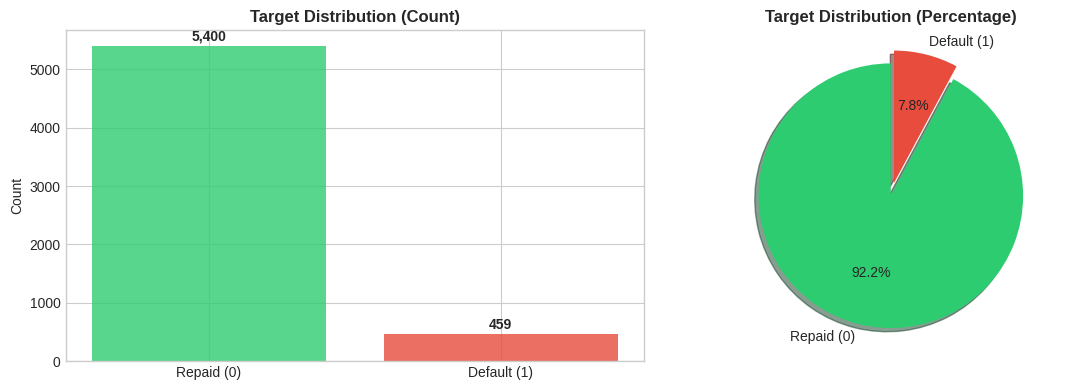

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------------------
# Step 2.1: Class Imbalance Analysis
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 2.1: CLASS IMBALANCE ANALYSIS")
print("="*70)

# Target distribution
target_counts = train['TARGET'].value_counts()
target_pct = train['TARGET'].value_counts(normalize=True) * 100

print("\n📊 TARGET DISTRIBUTION:")
print(f"   Repaid (0):  {target_counts[0]:,} ({target_pct[0]:.2f}%)")
print(f"   Default (1): {target_counts[1]:,} ({target_pct[1]:.2f}%)")
print(f"\n   Imbalance Ratio: {target_counts[0]/target_counts[1]:.1f}:1")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot
colors = ['#2ecc71', '#e74c3c']
bars = axes[0].bar(['Repaid (0)', 'Default (1)'], target_counts.values, color=colors, alpha=0.8)
axes[0].set_title('Target Distribution (Count)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 100, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(target_counts.values, labels=['Repaid (0)', 'Default (1)'],
            autopct='%1.1f%%', colors=colors, explode=[0, 0.1],
            shadow=True, startangle=90)
axes[1].set_title('Target Distribution (Percentage)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('step2_1_class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

**IDENTIFYING SENSITIVE/PROTECTED ATTRIBUTES**

In lending, certain attributes are legally protected or ethically sensitive.
Models should NOT discriminate based on these characteristics.

Protected attributes typically include:
- Gender / Sex
- Age
- Marital Status

We must analyze if our model treats different groups fairly


📌 SENSITIVE ATTRIBUTES IDENTIFIED IN DATASET:
--------------------------------------------------
   • CODE_GENDER: Gender (M/F)
   • NAME_FAMILY_STATUS: Marital Status
   • DAYS_BIRTH: Age (derived from DAYS_BIRTH)
   • NAME_EDUCATION_TYPE: Education Level
   • NAME_INCOME_TYPE: Income Type/Employment

📊 DISTRIBUTION OF SENSITIVE ATTRIBUTES

📌 1. GENDER (CODE_GENDER)
--------------------------------------------------
CODE_GENDER
F    3853
M    2006
Name: count, dtype: int64

Gender ratio (F:M): 1.92:1

📌 2. MARITAL STATUS (NAME_FAMILY_STATUS)
--------------------------------------------------
NAME_FAMILY_STATUS
Married                 3772
Single / not married     899
Civil marriage           545
Separated                355
Widow                    288
Name: count, dtype: int64

📌 3. AGE DISTRIBUTION
--------------------------------------------------
Age Range: 21 to 69 years
Mean Age: 43.9 years
Median Age: 43.2 years

📌 4. EDUCATION LEVEL (NAME_EDUCATION_TYPE)
---------------------

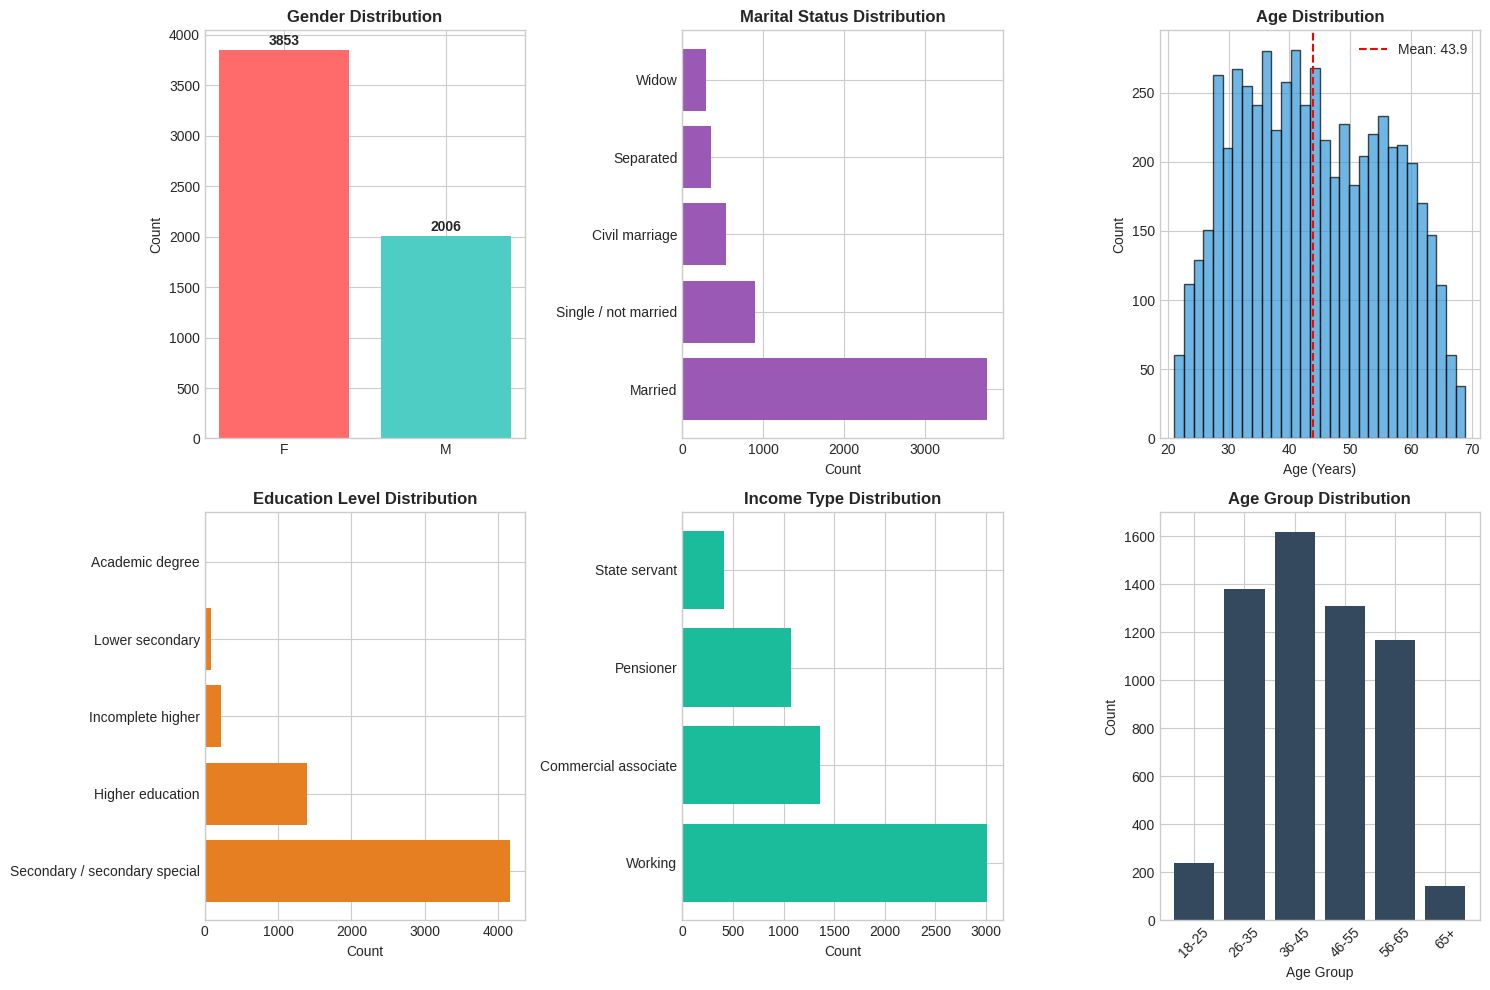


⚠️  RAI OBSERVATIONS:

1. GENDER IMBALANCE: More females (65.8%) than males (34.2%)
   → Need to check if default rates differ significantly by gender

2. MARITAL STATUS: Married applicants dominate (64.4%)
   → Check if single/widowed applicants face different outcomes

3. AGE DISTRIBUTION: Mean age ~44 years
   → Young and elderly applicants may face different treatment

4. EDUCATION: Majority have secondary education (71.1%)
   → Higher education applicants are minority - check fairness

5. INCOME TYPE: Working class dominates (51.4%)
   → Pensioners may face different model behavior

✅ NEXT STEP: Analyze default rates across these protected groups



In [40]:
# --------------------------------------------------------------
# Define sensitive attributes in our dataset
# --------------------------------------------------------------
print("\n📌 SENSITIVE ATTRIBUTES IDENTIFIED IN DATASET:")
print("-"*50)

sensitive_attributes = {
    'CODE_GENDER': 'Gender (M/F)',
    'NAME_FAMILY_STATUS': 'Marital Status',
    'DAYS_BIRTH': 'Age (derived from DAYS_BIRTH)',
    'NAME_EDUCATION_TYPE': 'Education Level',
    'NAME_INCOME_TYPE': 'Income Type/Employment'
}

for col, desc in sensitive_attributes.items():
    print(f"   • {col}: {desc}")

# --------------------------------------------------------------
# Analyze each sensitive attribute
# --------------------------------------------------------------
print("\n" + "="*70)
print("📊 DISTRIBUTION OF SENSITIVE ATTRIBUTES")
print("="*70)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

# 1. Gender Distribution
print("\n📌 1. GENDER (CODE_GENDER)")
print("-"*50)
gender_counts = train['CODE_GENDER'].value_counts()
print(gender_counts)
print(f"\nGender ratio (F:M): {gender_counts['F']/gender_counts['M']:.2f}:1")

axes[0].bar(gender_counts.index, gender_counts.values, color=['#ff6b6b', '#4ecdc4'])
axes[0].set_title('Gender Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(gender_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# 2. Marital Status Distribution
print("\n📌 2. MARITAL STATUS (NAME_FAMILY_STATUS)")
print("-"*50)
marital_counts = train['NAME_FAMILY_STATUS'].value_counts()
print(marital_counts)

axes[1].barh(marital_counts.index, marital_counts.values, color='#9b59b6')
axes[1].set_title('Marital Status Distribution', fontweight='bold')
axes[1].set_xlabel('Count')

# 3. Age Distribution
print("\n📌 3. AGE DISTRIBUTION")
print("-"*50)
train['AGE_YEARS'] = train['DAYS_BIRTH'] / -365
test['AGE_YEARS'] = test['DAYS_BIRTH'] / -365

print(f"Age Range: {train['AGE_YEARS'].min():.0f} to {train['AGE_YEARS'].max():.0f} years")
print(f"Mean Age: {train['AGE_YEARS'].mean():.1f} years")
print(f"Median Age: {train['AGE_YEARS'].median():.1f} years")

axes[2].hist(train['AGE_YEARS'], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[2].set_title('Age Distribution', fontweight='bold')
axes[2].set_xlabel('Age (Years)')
axes[2].set_ylabel('Count')
axes[2].axvline(train['AGE_YEARS'].mean(), color='red', linestyle='--', label=f'Mean: {train["AGE_YEARS"].mean():.1f}')
axes[2].legend()

# 4. Education Level Distribution
print("\n📌 4. EDUCATION LEVEL (NAME_EDUCATION_TYPE)")
print("-"*50)
edu_counts = train['NAME_EDUCATION_TYPE'].value_counts()
print(edu_counts)

axes[3].barh(edu_counts.index, edu_counts.values, color='#e67e22')
axes[3].set_title('Education Level Distribution', fontweight='bold')
axes[3].set_xlabel('Count')

# 5. Income Type Distribution
print("\n📌 5. INCOME TYPE (NAME_INCOME_TYPE)")
print("-"*50)
income_counts = train['NAME_INCOME_TYPE'].value_counts()
print(income_counts)

axes[4].barh(income_counts.index, income_counts.values, color='#1abc9c')
axes[4].set_title('Income Type Distribution', fontweight='bold')
axes[4].set_xlabel('Count')

# 6. Create Age Groups for fairness analysis
print("\n📌 6. AGE GROUPS (for fairness analysis)")
print("-"*50)

train['AGE_GROUP'] = pd.cut(train['AGE_YEARS'],
                            bins=[0, 25, 35, 45, 55, 65, 100],
                            labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])
test['AGE_GROUP'] = pd.cut(test['AGE_YEARS'],
                           bins=[0, 25, 35, 45, 55, 65, 100],
                           labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

age_group_counts = train['AGE_GROUP'].value_counts().sort_index()
print(age_group_counts)

axes[5].bar(age_group_counts.index.astype(str), age_group_counts.values, color='#34495e')
axes[5].set_title('Age Group Distribution', fontweight='bold')
axes[5].set_xlabel('Age Group')
axes[5].set_ylabel('Count')
axes[5].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('step2_2_sensitive_attributes.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
⚠️  RAI OBSERVATIONS:

1. GENDER IMBALANCE: More females ({:.1f}%) than males ({:.1f}%)
   → Need to check if default rates differ significantly by gender

2. MARITAL STATUS: Married applicants dominate ({:.1f}%)
   → Check if single/widowed applicants face different outcomes

3. AGE DISTRIBUTION: Mean age ~{:.0f} years
   → Young and elderly applicants may face different treatment

4. EDUCATION: Majority have secondary education ({:.1f}%)
   → Higher education applicants are minority - check fairness

5. INCOME TYPE: Working class dominates ({:.1f}%)
   → Pensioners may face different model behavior

✅ NEXT STEP: Analyze default rates across these protected groups
""".format(
    gender_counts['F']/len(train)*100,
    gender_counts['M']/len(train)*100,
    marital_counts['Married']/len(train)*100,
    train['AGE_YEARS'].mean(),
    edu_counts['Secondary / secondary special']/len(train)*100,
    income_counts['Working']/len(train)*100
))

**ANALYZING DEFAULT RATES BY SENSITIVE ATTRIBUTES**

We need to check if default rates (and thus potential denial rates)
differ significantly across protected groups. Large disparities may
indicate:
- Historical bias in the data
- Potential for discriminatory outcomes
- Need for fairness interventions

Legal standard: "80% rule" - if a group's favorable outcome rate is
less than 80% of the highest group's rate, there may be disparate impact.


📌 DEFAULT RATE BY GENDER
------------------------------------------------------------
             Total  Defaults  Default_Rate_Pct  Repayment_Rate_Pct
CODE_GENDER                                                       
M             2006       207             10.32               89.68
F             3853       252              6.54               93.46

   Disparate Impact Ratio: 0.960
   ✅ Within acceptable range (≥0.8)

📌 DEFAULT RATE BY AGE GROUP
------------------------------------------------------------
           Total  Defaults  Default_Rate_Pct  Repayment_Rate_Pct
AGE_GROUP                                                       
18-25        240        28             11.67               88.33
26-35       1380       139             10.07               89.93
36-45       1618       148              9.15               90.85
46-55       1309        81              6.19               93.81
56-65       1167        61              5.23               94.77
65+          145         2    

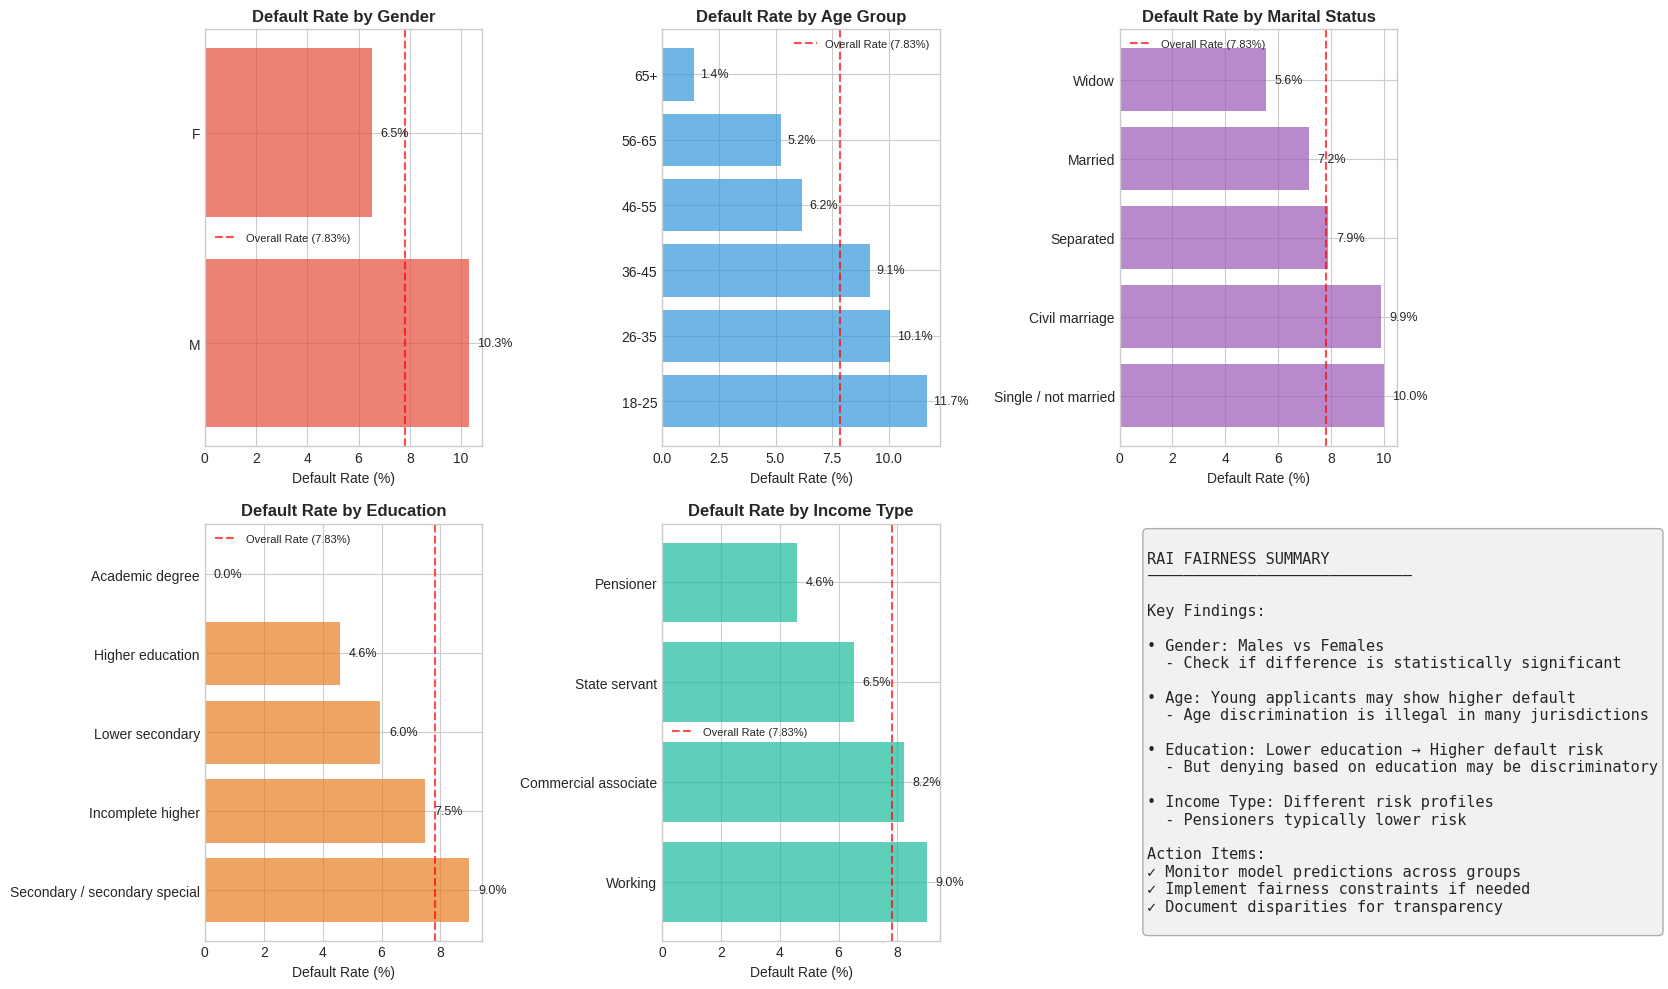


📊 STATISTICAL SIGNIFICANCE TESTS

📌 Chi-Square Test: Gender vs Default
   Chi-square statistic: 25.5665
   P-value: 0.0000
   ⚠️  SIGNIFICANT: Gender and Default are statistically associated

📌 Chi-Square Test: Age Group vs Default
   Chi-square statistic: 42.5864
   P-value: 0.0000
   ⚠️  SIGNIFICANT: Age Group and Default are statistically associated


In [42]:
# Function to calculate and display default rates
def analyze_default_rate(column, title):
    """Analyze default rates by a categorical column"""
    analysis = train.groupby(column)['TARGET'].agg(['sum', 'count', 'mean'])
    analysis.columns = ['Defaults', 'Total', 'Default_Rate']
    analysis['Default_Rate_Pct'] = analysis['Default_Rate'] * 100
    analysis['Repayment_Rate_Pct'] = 100 - analysis['Default_Rate_Pct']
    analysis = analysis.sort_values('Default_Rate_Pct', ascending=False)

    print(f"\n📌 {title}")
    print("-"*60)
    print(analysis[['Total', 'Defaults', 'Default_Rate_Pct', 'Repayment_Rate_Pct']].round(2).to_string())

    # Calculate disparate impact ratio
    max_repayment = analysis['Repayment_Rate_Pct'].max()
    min_repayment = analysis['Repayment_Rate_Pct'].min()
    disparate_impact = min_repayment / max_repayment

    print(f"\n   Disparate Impact Ratio: {disparate_impact:.3f}")
    if disparate_impact < 0.8:
        print(f"   ⚠️  POTENTIAL DISPARATE IMPACT DETECTED (<0.8)")
    else:
        print(f"   ✅ Within acceptable range (≥0.8)")

    return analysis

# --------------------------------------------------------------
# 1. Default Rate by Gender
# --------------------------------------------------------------
gender_analysis = analyze_default_rate('CODE_GENDER', 'DEFAULT RATE BY GENDER')

# --------------------------------------------------------------
# 2. Default Rate by Age Group
# --------------------------------------------------------------
age_analysis = analyze_default_rate('AGE_GROUP', 'DEFAULT RATE BY AGE GROUP')

# --------------------------------------------------------------
# 3. Default Rate by Marital Status
# --------------------------------------------------------------
marital_analysis = analyze_default_rate('NAME_FAMILY_STATUS', 'DEFAULT RATE BY MARITAL STATUS')

# --------------------------------------------------------------
# 4. Default Rate by Education
# --------------------------------------------------------------
edu_analysis = analyze_default_rate('NAME_EDUCATION_TYPE', 'DEFAULT RATE BY EDUCATION')

# --------------------------------------------------------------
# 5. Default Rate by Income Type
# --------------------------------------------------------------
income_analysis = analyze_default_rate('NAME_INCOME_TYPE', 'DEFAULT RATE BY INCOME TYPE')

# --------------------------------------------------------------
# Visualization
# --------------------------------------------------------------
print("\n" + "="*70)
print("📊 VISUALIZING DEFAULT RATES BY PROTECTED GROUPS")
print("="*70)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Helper function for plotting
def plot_default_rate(ax, data, title, color):
    categories = data.index.astype(str)
    default_rates = data['Default_Rate_Pct'].values

    bars = ax.barh(categories, default_rates, color=color, alpha=0.7)
    ax.set_xlabel('Default Rate (%)')
    ax.set_title(title, fontweight='bold')
    ax.axvline(x=7.83, color='red', linestyle='--', alpha=0.7, label='Overall Rate (7.83%)')

    # Add value labels
    for i, v in enumerate(default_rates):
        ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)

    ax.legend(fontsize=8)

# Plot each analysis
plot_default_rate(axes[0], gender_analysis, 'Default Rate by Gender', '#e74c3c')
plot_default_rate(axes[1], age_analysis.sort_index(), 'Default Rate by Age Group', '#3498db')
plot_default_rate(axes[2], marital_analysis, 'Default Rate by Marital Status', '#9b59b6')
plot_default_rate(axes[3], edu_analysis, 'Default Rate by Education', '#e67e22')
plot_default_rate(axes[4], income_analysis, 'Default Rate by Income Type', '#1abc9c')

# Summary statistics in last subplot
axes[5].axis('off')
summary_text = """
RAI FAIRNESS SUMMARY
─────────────────────────────

Key Findings:

• Gender: Males vs Females
  - Check if difference is statistically significant

• Age: Young applicants may show higher default
  - Age discrimination is illegal in many jurisdictions

• Education: Lower education → Higher default risk
  - But denying based on education may be discriminatory

• Income Type: Different risk profiles
  - Pensioners typically lower risk

Action Items:
✓ Monitor model predictions across groups
✓ Implement fairness constraints if needed
✓ Document disparities for transparency
"""
axes[5].text(0.1, 0.5, summary_text, transform=axes[5].transAxes,
             fontsize=11, verticalalignment='center', fontfamily='monospace',
             bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.3))

plt.tight_layout()
plt.savefig('step2_3_default_rates_by_groups.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Statistical Significance Test
# --------------------------------------------------------------
print("\n" + "="*70)
print("📊 STATISTICAL SIGNIFICANCE TESTS")
print("="*70)

from scipy import stats

# Chi-square test for Gender vs Default
print("\n📌 Chi-Square Test: Gender vs Default")
contingency_gender = pd.crosstab(train['CODE_GENDER'], train['TARGET'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_gender)
print(f"   Chi-square statistic: {chi2:.4f}")
print(f"   P-value: {p_value:.4f}")
if p_value < 0.05:
    print("   ⚠️  SIGNIFICANT: Gender and Default are statistically associated")
else:
    print("   ✅ NOT SIGNIFICANT: No statistical association between Gender and Default")

# Chi-square test for Age Group vs Default
print("\n📌 Chi-Square Test: Age Group vs Default")
contingency_age = pd.crosstab(train['AGE_GROUP'], train['TARGET'])
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_age)
print(f"   Chi-square statistic: {chi2:.4f}")
print(f"   P-value: {p_value:.4f}")
if p_value < 0.05:
    print("   ⚠️  SIGNIFICANT: Age Group and Default are statistically associated")
else:
    print("   ✅ NOT SIGNIFICANT: No statistical association between Age Group and Default")


**RAI Concerns Identified:**

Gender Bias Risk: Males are 1.6x more likely to default than females (10.3% vs 6.5%). This is statistically significant (p < 0.0001) — if the model learns this pattern, it may unfairly penalize male applicants.

Age Bias Risk: Young applicants (18-25) are 8.5x more likely to default than elderly (65+). This is statistically significant (p < 0.0001) — age-based discrimination is illegal in many jurisdictions.

Disparate Impact: All groups pass the 80% rule (≥ 0.8), but statistical significance means we must monitor model fairness and apply bias mitigation if needed.

**FEATURE ENGINEERING**

Focus behind feature engineering: creating meaningful features while being mindful of proxy discrimination - features that indirectly encode protected attributes

In [43]:
# --------------------------------------------------------------
# Step 3.1: Create Meaningful Derived Features
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.1: CREATE DERIVED FEATURES")
print("="*70)

# Store original column count
original_cols = train.shape[1]

# 1. Age feature (already created, but verify)
print("\n📌 1. AGE FEATURES")
print("-"*50)

if 'AGE_YEARS' not in train.columns:
    train['AGE_YEARS'] = train['DAYS_BIRTH'] / -365
    test['AGE_YEARS'] = test['DAYS_BIRTH'] / -365

print(f"   ✅ AGE_YEARS: Range [{train['AGE_YEARS'].min():.1f}, {train['AGE_YEARS'].max():.1f}]")
print(f"   📋 Reason: Converts days to interpretable years for better explainability")

# 2. Employment features
print("\n📌 2. EMPLOYMENT FEATURES")
print("-"*50)

train['EMPLOYMENT_YEARS'] = train['DAYS_EMPLOYED'] / -365
test['EMPLOYMENT_YEARS'] = test['DAYS_EMPLOYED'] / -365

train['EMPLOYMENT_TO_AGE_RATIO'] = train['EMPLOYMENT_YEARS'] / (train['AGE_YEARS'] + 1)
test['EMPLOYMENT_TO_AGE_RATIO'] = test['EMPLOYMENT_YEARS'] / (test['AGE_YEARS'] + 1)

print(f"   ✅ EMPLOYMENT_YEARS: Range [{train['EMPLOYMENT_YEARS'].min():.1f}, {train['EMPLOYMENT_YEARS'].max():.1f}]")
print(f"   📋 Reason: Job stability is a key indicator of repayment ability")
print(f"   ✅ EMPLOYMENT_TO_AGE_RATIO: Career stability relative to age")
print(f"   📋 Reason: Young person with 5 years experience differs from older person with same")

# 3. Financial ratios
print("\n📌 3. FINANCIAL RATIOS")
print("-"*50)

train['CREDIT_INCOME_RATIO'] = train['AMT_CREDIT'] / (train['AMT_INCOME_TOTAL'] + 1)
test['CREDIT_INCOME_RATIO'] = test['AMT_CREDIT'] / (test['AMT_INCOME_TOTAL'] + 1)

train['ANNUITY_INCOME_RATIO'] = train['AMT_ANNUITY'] / (train['AMT_INCOME_TOTAL'] + 1)
test['ANNUITY_INCOME_RATIO'] = test['AMT_ANNUITY'] / (test['AMT_INCOME_TOTAL'] + 1)

train['CREDIT_GOODS_RATIO'] = train['AMT_CREDIT'] / (train['AMT_GOODS_PRICE'] + 1)
test['CREDIT_GOODS_RATIO'] = test['AMT_CREDIT'] / (test['AMT_GOODS_PRICE'] + 1)

train['INCOME_PER_FAMILY'] = train['AMT_INCOME_TOTAL'] / (train['CNT_FAM_MEMBERS'] + 1)
test['INCOME_PER_FAMILY'] = test['AMT_INCOME_TOTAL'] / (test['CNT_FAM_MEMBERS'] + 1)

train['LOAN_TERM_MONTHS'] = train['AMT_CREDIT'] / (train['AMT_ANNUITY'] + 1)
test['LOAN_TERM_MONTHS'] = test['AMT_CREDIT'] / (test['AMT_ANNUITY'] + 1)

print(f"   ✅ CREDIT_INCOME_RATIO: How much debt relative to income")
print(f"   📋 Reason: High ratio = higher risk, standard banking metric")
print(f"   ✅ ANNUITY_INCOME_RATIO: Monthly payment burden")
print(f"   📋 Reason: Measures if applicant can afford monthly payments")
print(f"   ✅ CREDIT_GOODS_RATIO: Loan-to-value ratio")
print(f"   📋 Reason: Values >1 mean borrowing more than goods worth (higher risk)")
print(f"   ✅ INCOME_PER_FAMILY: Per-capita household income")
print(f"   📋 Reason: Large families with same income have less disposable money")
print(f"   ✅ LOAN_TERM_MONTHS: Estimated loan duration")
print(f"   📋 Reason: Longer loans = more uncertainty = higher risk")

# 4. External source features
print("\n📌 4. EXTERNAL SOURCE FEATURES (Credit Scores)")
print("-"*50)

train['EXT_SOURCE_MEAN'] = train[['EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
test['EXT_SOURCE_MEAN'] = test[['EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)

train['EXT_SOURCE_PROD'] = train['EXT_SOURCE_2'] * train['EXT_SOURCE_3']
test['EXT_SOURCE_PROD'] = test['EXT_SOURCE_2'] * test['EXT_SOURCE_3']

train['EXT_SOURCE_MIN'] = train[['EXT_SOURCE_2', 'EXT_SOURCE_3']].min(axis=1)
test['EXT_SOURCE_MIN'] = test[['EXT_SOURCE_2', 'EXT_SOURCE_3']].min(axis=1)

print(f"   ✅ EXT_SOURCE_MEAN: Average of external credit scores")
print(f"   📋 Reason: Combines multiple credit assessments for robust score")
print(f"   ✅ EXT_SOURCE_PROD: Product of credit scores")
print(f"   📋 Reason: Captures interaction - low score in ANY source is risky")
print(f"   ✅ EXT_SOURCE_MIN: Minimum credit score")
print(f"   📋 Reason: Weakest link principle - lowest score matters most")

# 5. Document aggregation
print("\n📌 5. DOCUMENT FLAG AGGREGATION")
print("-"*50)

doc_cols = [col for col in train.columns if 'FLAG_DOCUMENT' in col]
train['TOTAL_DOCUMENTS'] = train[doc_cols].sum(axis=1)
test['TOTAL_DOCUMENTS'] = test[doc_cols].sum(axis=1)

print(f"   ✅ TOTAL_DOCUMENTS: Count of documents submitted ({len(doc_cols)} flags)")
print(f"   📋 Reason: More documents = more serious applicant = lower risk")

# 6. Credit bureau aggregation
print("\n📌 6. CREDIT BUREAU AGGREGATION")
print("-"*50)

bureau_cols = [col for col in train.columns if 'AMT_REQ_CREDIT_BUREAU' in col]
train['TOTAL_BUREAU_REQUESTS'] = train[bureau_cols].sum(axis=1)
test['TOTAL_BUREAU_REQUESTS'] = test[bureau_cols].sum(axis=1)

print(f"   ✅ TOTAL_BUREAU_REQUESTS: Total credit inquiries ({len(bureau_cols)} types)")
print(f"   📋 Reason: Many recent inquiries = desperate for credit = higher risk")

# 7. Social circle risk
print("\n📌 7. SOCIAL CIRCLE FEATURES")
print("-"*50)

train['SOCIAL_CIRCLE_DEFAULT_RATIO'] = train['DEF_30_CNT_SOCIAL_CIRCLE'] / (train['OBS_30_CNT_SOCIAL_CIRCLE'] + 1)
test['SOCIAL_CIRCLE_DEFAULT_RATIO'] = test['DEF_30_CNT_SOCIAL_CIRCLE'] / (test['OBS_30_CNT_SOCIAL_CIRCLE'] + 1)

print(f"   ✅ SOCIAL_CIRCLE_DEFAULT_RATIO: Default rate in applicant's network")
print(f"   📋 Reason: People in high-default networks may have similar risk profiles")

# --------------------------------------------------------------
# Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ FEATURE ENGINEERING COMPLETE")
print("="*70)

new_features = ['AGE_YEARS', 'EMPLOYMENT_YEARS', 'EMPLOYMENT_TO_AGE_RATIO',
                'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_GOODS_RATIO',
                'INCOME_PER_FAMILY', 'LOAN_TERM_MONTHS', 'EXT_SOURCE_MEAN',
                'EXT_SOURCE_PROD', 'EXT_SOURCE_MIN', 'TOTAL_DOCUMENTS',
                'TOTAL_BUREAU_REQUESTS', 'SOCIAL_CIRCLE_DEFAULT_RATIO']

print(f"\nNew features created: {len(new_features)}")
print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

# --------------------------------------------------------------
# RAI Check: Proxy Variable Analysis
# --------------------------------------------------------------
print("\n" + "="*70)
print("⚠️  RAI CHECK: PROXY VARIABLE ANALYSIS")
print("="*70)

print("""
Checking if new features correlate strongly with protected attributes...
(High correlation may indicate proxy discrimination risk)
""")

# Encode gender temporarily for correlation
train['GENDER_ENCODED'] = (train['CODE_GENDER'] == 'M').astype(int)

proxy_features = ['CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'INCOME_PER_FAMILY',
                  'EMPLOYMENT_YEARS', 'EXT_SOURCE_MEAN']

print("Correlation with AGE_YEARS:")
for feat in proxy_features:
    corr = train[feat].corr(train['AGE_YEARS'])
    risk = "⚠️ HIGH PROXY RISK" if abs(corr) > 0.3 else "✅ LOW"
    print(f"   {feat}: {corr:.3f} {risk}")

print("\nCorrelation with GENDER:")
for feat in proxy_features:
    corr = train[feat].corr(train['GENDER_ENCODED'])
    risk = "⚠️ HIGH PROXY RISK" if abs(corr) > 0.3 else "✅ LOW"
    print(f"   {feat}: {corr:.3f} {risk}")

# Drop temporary column
train = train.drop(columns=['GENDER_ENCODED'])

print("""
📋 RAI INTERPRETATION:
- LOW correlation (< 0.3): Feature is independent of protected attribute ✅
- HIGH correlation (> 0.3): Feature may act as proxy for protected attribute ⚠️
  → Monitor this feature's impact on fairness metrics
""")


STEP 3.1: CREATE DERIVED FEATURES

📌 1. AGE FEATURES
--------------------------------------------------
   ✅ AGE_YEARS: Range [21.0, 69.0]
   📋 Reason: Converts days to interpretable years for better explainability

📌 2. EMPLOYMENT FEATURES
--------------------------------------------------
   ✅ EMPLOYMENT_YEARS: Range [0.1, 44.4]
   📋 Reason: Job stability is a key indicator of repayment ability
   ✅ EMPLOYMENT_TO_AGE_RATIO: Career stability relative to age
   📋 Reason: Young person with 5 years experience differs from older person with same

📌 3. FINANCIAL RATIOS
--------------------------------------------------
   ✅ CREDIT_INCOME_RATIO: How much debt relative to income
   📋 Reason: High ratio = higher risk, standard banking metric
   ✅ ANNUITY_INCOME_RATIO: Monthly payment burden
   📋 Reason: Measures if applicant can afford monthly payments
   ✅ CREDIT_GOODS_RATIO: Loan-to-value ratio
   📋 Reason: Values >1 mean borrowing more than goods worth (higher risk)
   ✅ INCOME_PER_FAMILY

All new features have LOW proxy risk (correlation < 0.3) with protected attributes. This is exactly what we need for fairness.

**ENCODING & SCALING FEATURES**

In [45]:
# --------------------------------------------------------------
# Step 3.2: Encode Categorical Variables
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.2: ENCODE CATEGORICAL VARIABLES")
print("="*70)

from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()

print(f"\n📌 Categorical columns to encode ({len(categorical_cols)}):")
for col in categorical_cols:
    print(f"   • {col}: {train[col].nunique()} unique values")

# Store label encoders for interpretability later
label_encoders = {}

print("\n📌 Encoding...")
for col in categorical_cols:
    le = LabelEncoder()

    # Fit on combined train + test to handle all values
    combined_values = list(train[col].astype(str).values) + list(test[col].astype(str).values)
    le.fit(combined_values)

    # Transform
    train[col] = le.transform(train[col].astype(str))
    test[col] = le.transform(test[col].astype(str))

    # Store encoder
    label_encoders[col] = le
    print(f"   ✅ {col}: encoded {len(le.classes_)} classes")

print("""
📋 RAI NOTE:
We stored label encoders for later interpretability. This allows us to
convert encoded predictions back to human-readable categories when
generating explanations.
""")

# --------------------------------------------------------------
# Step 3.3: Prepare Final Feature Set
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.3: PREPARE FINAL FEATURE SET")
print("="*70)

# Drop AGE_GROUP (categorical, already have AGE_YEARS)
if 'AGE_GROUP' in train.columns:
    train = train.drop(columns=['AGE_GROUP'])
    test = test.drop(columns=['AGE_GROUP'])
    print("   ✅ Dropped AGE_GROUP (redundant with AGE_YEARS)")

# Define features and target
exclude_cols = ['SK_ID_CURR', 'TARGET']
feature_cols = [col for col in train.columns if col not in exclude_cols]

X = train[feature_cols]
y = train['TARGET']
X_test_final = test[feature_cols]
test_ids = test['SK_ID_CURR']

print(f"\n📌 Final Feature Set:")
print(f"   • Number of features: {len(feature_cols)}")
print(f"   • Training samples: {X.shape[0]}")
print(f"   • Test samples: {X_test_final.shape[0]}")

# --------------------------------------------------------------
# Step 3.4: Train-Validation Split
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.4: TRAIN-VALIDATION SPLIT")
print("="*70)

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Important for imbalanced data
)

print(f"\n📌 Split Results:")
print(f"   • X_train: {X_train.shape}")
print(f"   • X_val: {X_val.shape}")
print(f"   • y_train distribution: {dict(y_train.value_counts())}")
print(f"   • y_val distribution: {dict(y_val.value_counts())}")
print(f"\n   • Train default rate: {y_train.mean()*100:.2f}%")
print(f"   • Val default rate: {y_val.mean()*100:.2f}%")

print("""
📋 RAI NOTE:
We used stratified split to ensure both train and validation sets have
the same class distribution. This prevents evaluation bias.
""")

# --------------------------------------------------------------
# Step 3.5: Feature Scaling
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.5: FEATURE SCALING")
print("="*70)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data only (prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_final)

# Convert back to DataFrame for interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=feature_cols, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test_final.index)

print(f"   ✅ Scaling complete (StandardScaler)")
print(f"   • Fitted on training data only (no data leakage)")
print(f"   • Mean ≈ 0, Std ≈ 1 for all features")

print("""
📋 RAI NOTE:
We fit the scaler on training data only and transform validation/test
separately. This prevents data leakage and ensures fair evaluation.
""")

# --------------------------------------------------------------
# Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ PHASE 3 COMPLETE: DATA READY FOR MODELING")
print("="*70)

print(f"""
DATASETS PREPARED:
──────────────────
• X_train_scaled: {X_train_scaled.shape} - Training features
• X_val_scaled: {X_val_scaled.shape} - Validation features
• X_test_scaled: {X_test_scaled.shape} - Test features (for final predictions)

• y_train: {y_train.shape} - Training labels
• y_val: {y_val.shape} - Validation labels

• feature_cols: {len(feature_cols)} features
• test_ids: {len(test_ids)} IDs for submission

CLASS DISTRIBUTION:
───────────────────
• Default rate (Train): {y_train.mean()*100:.2f}%
• Default rate (Val): {y_val.mean()*100:.2f}%
• Imbalance ratio: {(1-y_train.mean())/y_train.mean():.1f}:1


""")


STEP 3.2: ENCODE CATEGORICAL VARIABLES

📌 Categorical columns to encode (0):

📌 Encoding...

📋 RAI NOTE: 
We stored label encoders for later interpretability. This allows us to 
convert encoded predictions back to human-readable categories when 
generating explanations.


STEP 3.3: PREPARE FINAL FEATURE SET

📌 Final Feature Set:
   • Number of features: 81
   • Training samples: 5859
   • Test samples: 1950

STEP 3.4: TRAIN-VALIDATION SPLIT

📌 Split Results:
   • X_train: (4687, 81)
   • X_val: (1172, 81)
   • y_train distribution: {0: np.int64(4320), 1: np.int64(367)}
   • y_val distribution: {0: np.int64(1080), 1: np.int64(92)}

   • Train default rate: 7.83%
   • Val default rate: 7.85%

📋 RAI NOTE: 
We used stratified split to ensure both train and validation sets have 
the same class distribution. This prevents evaluation bias.


STEP 3.5: FEATURE SCALING
   ✅ Scaling complete (StandardScaler)
   • Fitted on training data only (no data leakage)
   • Mean ≈ 0, Std ≈ 1 for all feat

**FEATURE SELECTION BASED ON IMPORTANCE**

Feature selection is necessary for a XAI model as it:


1.   Improves model interpretability
2.   Identifies which features drive predictions






📌 Initial features: 81

📌 1. RANDOM FOREST FEATURE IMPORTANCE
--------------------------------------------------

🔝 TOP 20 MOST IMPORTANT FEATURES:
                   feature  importance
           EXT_SOURCE_MEAN    0.073939
           EXT_SOURCE_PROD    0.072451
            EXT_SOURCE_MIN    0.068930
              EXT_SOURCE_3    0.057080
              EXT_SOURCE_2    0.051351
                 AGE_YEARS    0.036162
        CREDIT_GOODS_RATIO    0.034847
                DAYS_BIRTH    0.034821
          LOAN_TERM_MONTHS    0.032250
           DAYS_ID_PUBLISH    0.027222
                AMT_CREDIT    0.026258
               AMT_ANNUITY    0.025554
    DAYS_LAST_PHONE_CHANGE    0.025149
         DAYS_REGISTRATION    0.025068
   EMPLOYMENT_TO_AGE_RATIO    0.024581
             DAYS_EMPLOYED    0.024167
       CREDIT_INCOME_RATIO    0.024124
           AMT_GOODS_PRICE    0.023404
REGION_POPULATION_RELATIVE    0.022054
          EMPLOYMENT_YEARS    0.021949

🔻 BOTTOM 10 LEAST IMPORTANT FEA

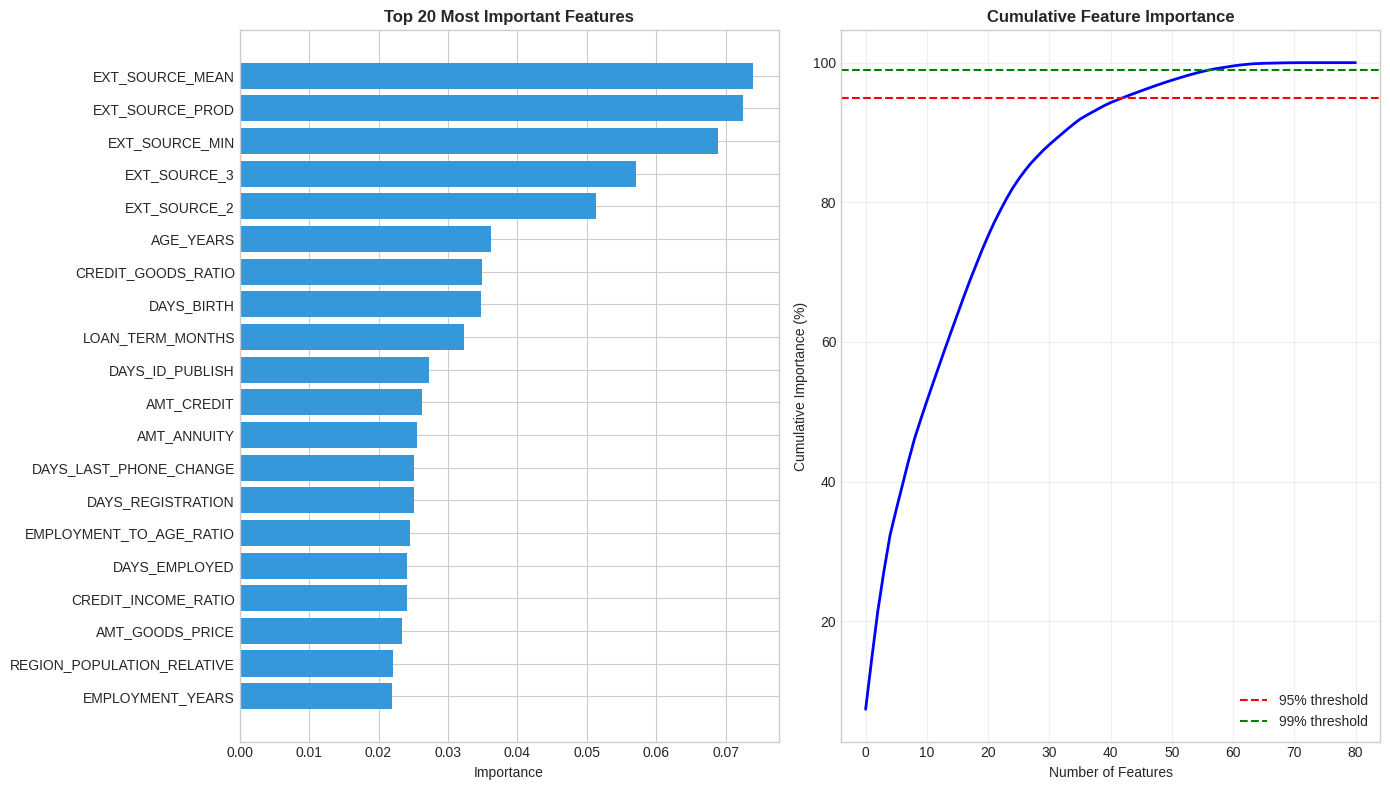


📌 3. SELECTING FEATURES
--------------------------------------------------
   • Features for 95% importance: 44
   • Features for 99% importance: 58
   • Features with importance < 0.001: 19

✅ SELECTED FEATURES: 62 (removed 19 low-importance features)

📌 4. RAI CHECK: PROTECTED ATTRIBUTES IN TOP FEATURES
--------------------------------------------------

Importance of Protected Attributes:
   • CODE_GENDER: importance=0.0075, rank=2/81 ✅ LOW INFLUENCE
   • AGE_YEARS: importance=0.0362, rank=68/81 ⚠️ HIGH INFLUENCE
   • NAME_FAMILY_STATUS: importance=0.0071, rank=13/81 ✅ LOW INFLUENCE
   • NAME_EDUCATION_TYPE: importance=0.0131, rank=12/81 ✅ LOW INFLUENCE
   • NAME_INCOME_TYPE: importance=0.0047, rank=11/81 ✅ LOW INFLUENCE

✅ FEATURE SELECTION COMPLETE

SUMMARY:
────────
• Initial features: 81
• Selected features: 62
• Removed features: 19

SELECTION CRITERIA:
───────────────────
• Kept features with importance >= 0.001


📋 Feature list saved to 'feature_cols' (62 features)


In [46]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# First, let's prepare data for feature selection
exclude_cols = ['SK_ID_CURR', 'TARGET', 'AGE_GROUP']
feature_cols_temp = [col for col in train.columns if col not in exclude_cols]

X_temp = train[feature_cols_temp]
y_temp = train['TARGET']

print(f"\n📌 Initial features: {len(feature_cols_temp)}")

# --------------------------------------------------------------
# Method 1: Random Forest Feature Importance
# --------------------------------------------------------------
print("\n📌 1. RANDOM FOREST FEATURE IMPORTANCE")
print("-"*50)

rf_selector = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_selector.fit(X_temp, y_temp)

# Get feature importances
feature_importance = pd.DataFrame({
    'feature': feature_cols_temp,
    'importance': rf_selector.feature_importances_
}).sort_values('importance', ascending=False)

print("\n🔝 TOP 20 MOST IMPORTANT FEATURES:")
print(feature_importance.head(20).to_string(index=False))

print("\n🔻 BOTTOM 10 LEAST IMPORTANT FEATURES:")
print(feature_importance.tail(10).to_string(index=False))

# --------------------------------------------------------------
# Visualize Feature Importance
# --------------------------------------------------------------
print("\n📌 2. VISUALIZING FEATURE IMPORTANCE")
print("-"*50)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Top 20 features
top_20 = feature_importance.head(20)
axes[0].barh(top_20['feature'], top_20['importance'], color='#3498db')
axes[0].set_xlabel('Importance')
axes[0].set_title('Top 20 Most Important Features', fontweight='bold')
axes[0].invert_yaxis()

# Cumulative importance
feature_importance_sorted = feature_importance.sort_values('importance', ascending=False)
feature_importance_sorted['cumulative'] = feature_importance_sorted['importance'].cumsum()
feature_importance_sorted['cumulative_pct'] = feature_importance_sorted['cumulative'] / feature_importance_sorted['importance'].sum() * 100

axes[1].plot(range(len(feature_importance_sorted)), feature_importance_sorted['cumulative_pct'], 'b-', linewidth=2)
axes[1].axhline(y=95, color='r', linestyle='--', label='95% threshold')
axes[1].axhline(y=99, color='g', linestyle='--', label='99% threshold')
axes[1].set_xlabel('Number of Features')
axes[1].set_ylabel('Cumulative Importance (%)')
axes[1].set_title('Cumulative Feature Importance', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('step3_4_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Select features (keep those contributing to 95% importance)
# --------------------------------------------------------------
print("\n📌 3. SELECTING FEATURES")
print("-"*50)

# Find number of features for 95% importance
n_features_95 = (feature_importance_sorted['cumulative_pct'] <= 95).sum() + 1
n_features_99 = (feature_importance_sorted['cumulative_pct'] <= 99).sum() + 1

print(f"   • Features for 95% importance: {n_features_95}")
print(f"   • Features for 99% importance: {n_features_99}")

# Also remove features with near-zero importance
importance_threshold = 0.001
low_importance_features = feature_importance[feature_importance['importance'] < importance_threshold]['feature'].tolist()
print(f"   • Features with importance < {importance_threshold}: {len(low_importance_features)}")

# Decision: Keep features with importance >= threshold
selected_features = feature_importance[feature_importance['importance'] >= importance_threshold]['feature'].tolist()

print(f"\n✅ SELECTED FEATURES: {len(selected_features)} (removed {len(feature_cols_temp) - len(selected_features)} low-importance features)")

# --------------------------------------------------------------
# RAI Check: Are protected attributes in top features?
# --------------------------------------------------------------
print("\n📌 4. RAI CHECK: PROTECTED ATTRIBUTES IN TOP FEATURES")
print("-"*50)

protected_attrs = ['CODE_GENDER', 'AGE_YEARS', 'NAME_FAMILY_STATUS',
                   'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']

print("\nImportance of Protected Attributes:")
for attr in protected_attrs:
    if attr in feature_importance['feature'].values:
        imp = feature_importance[feature_importance['feature'] == attr]['importance'].values[0]
        rank = feature_importance[feature_importance['feature'] == attr].index[0] + 1
        risk = "⚠️ HIGH INFLUENCE" if imp > 0.02 else "✅ LOW INFLUENCE"
        print(f"   • {attr}: importance={imp:.4f}, rank={rank}/{len(feature_cols_temp)} {risk}")
print("\n" + "="*70)
print("✅ FEATURE SELECTION COMPLETE")
print("="*70)

print(f"""
SUMMARY:
────────
• Initial features: {len(feature_cols_temp)}
• Selected features: {len(selected_features)}
• Removed features: {len(feature_cols_temp) - len(selected_features)}

SELECTION CRITERIA:
───────────────────
• Kept features with importance >= {importance_threshold}
""")

# Store selected features for next steps
feature_cols = selected_features
print(f"\n📋 Feature list saved to 'feature_cols' ({len(feature_cols)} features)")

If protected attributes have HIGH importance, the model may be making
  decisions heavily based on gender, age, etc. → potential discrimination
  
Will monitor this in fairness evaluation

**ENCODING, SPLITTING & SCALING FEATURES**

In [48]:
# --------------------------------------------------------------
# Step 3.5: Encode Categorical Variables
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.5: ENCODE CATEGORICAL VARIABLES")
print("="*70)

from sklearn.preprocessing import LabelEncoder

# Identify categorical columns in selected features
categorical_cols = [col for col in feature_cols if train[col].dtype == 'object']

print(f"\n📌 Categorical columns to encode ({len(categorical_cols)}):")
for col in categorical_cols:
    print(f"   • {col}: {train[col].nunique()} unique values")

# Store label encoders for interpretability later
label_encoders = {}

print("\n📌 Encoding...")
for col in categorical_cols:
    le = LabelEncoder()

    # Fit on combined train + test to handle all values
    combined_values = list(train[col].astype(str).values) + list(test[col].astype(str).values)
    le.fit(combined_values)

    # Transform
    train[col] = le.transform(train[col].astype(str))
    test[col] = le.transform(test[col].astype(str))

    # Store encoder
    label_encoders[col] = le
    print(f"   ✅ {col}: encoded {len(le.classes_)} classes")

print("""
📋 RAI NOTE:
Label encoders stored for later interpretability - allows converting
encoded predictions back to human-readable categories for explanations.
""")

# --------------------------------------------------------------
# Step 3.6: Prepare Final Dataset with Selected Features
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.6: PREPARE FINAL DATASET")
print("="*70)

# Prepare X and y with selected features only
X = train[feature_cols]
y = train['TARGET']
X_test_final = test[feature_cols]
test_ids = test['SK_ID_CURR']

print(f"\n📌 Final Dataset:")
print(f"   • Features used: {len(feature_cols)}")
print(f"   • Training samples: {X.shape[0]}")
print(f"   • Test samples: {X_test_final.shape[0]}")

# --------------------------------------------------------------
# Step 3.7: Train-Validation Split
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.7: TRAIN-VALIDATION SPLIT")
print("="*70)

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\n📌 Split Results (Stratified):")
print(f"   • X_train: {X_train.shape}")
print(f"   • X_val: {X_val.shape}")
print(f"   • y_train: 0={sum(y_train==0)}, 1={sum(y_train==1)}")
print(f"   • y_val: 0={sum(y_val==0)}, 1={sum(y_val==1)}")
print(f"\n   • Train default rate: {y_train.mean()*100:.2f}%")
print(f"   • Val default rate: {y_val.mean()*100:.2f}%")

print("""
📋 RAI NOTE:
Stratified split ensures equal class distribution in train/validation sets.
This prevents evaluation bias from uneven splits.
""")

# --------------------------------------------------------------
# Step 3.8: Feature Scaling
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 3.8: FEATURE SCALING")
print("="*70)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data only (prevent data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_final)

# Convert back to DataFrame for interpretability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=feature_cols, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_cols, index=X_test_final.index)

print(f"   ✅ StandardScaler applied")
print(f"   • Fitted on training data only (no data leakage)")
print(f"   • All features now have mean ≈ 0, std ≈ 1")

# --------------------------------------------------------------
# Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ PHASE 3 COMPLETE: DATA READY FOR MODELING")
print("="*70)

print(f"""
DATASETS PREPARED:
──────────────────
• X_train_scaled: {X_train_scaled.shape}
• X_val_scaled:   {X_val_scaled.shape}
• X_test_scaled:  {X_test_scaled.shape}

• y_train: {y_train.shape} (Default rate: {y_train.mean()*100:.2f}%)
• y_val:   {y_val.shape} (Default rate: {y_val.mean()*100:.2f}%)

• test_ids: {len(test_ids)} (for final submission)

KEY OBJECTS SAVED:
──────────────────
• feature_cols: List of {len(feature_cols)} selected features
• label_encoders: Dict of encoders for categorical variables
• scaler: StandardScaler fitted on training data
""")


STEP 3.5: ENCODE CATEGORICAL VARIABLES

📌 Categorical columns to encode (0):

📌 Encoding...

📋 RAI NOTE: 
Label encoders stored for later interpretability - allows converting 
encoded predictions back to human-readable categories for explanations.


STEP 3.6: PREPARE FINAL DATASET

📌 Final Dataset:
   • Features used: 62
   • Training samples: 5859
   • Test samples: 1950

STEP 3.7: TRAIN-VALIDATION SPLIT

📌 Split Results (Stratified):
   • X_train: (4687, 62)
   • X_val: (1172, 62)
   • y_train: 0=4320, 1=367
   • y_val: 0=1080, 1=92

   • Train default rate: 7.83%
   • Val default rate: 7.85%

📋 RAI NOTE: 
Stratified split ensures equal class distribution in train/validation sets.
This prevents evaluation bias from uneven splits.


STEP 3.8: FEATURE SCALING
   ✅ StandardScaler applied
   • Fitted on training data only (no data leakage)
   • All features now have mean ≈ 0, std ≈ 1

✅ PHASE 3 COMPLETE: DATA READY FOR MODELING

DATASETS PREPARED:
──────────────────
• X_train_scaled: (4

**HANDLING CLASS IMBALANCE**

Class imbalance handling is directly related to responsible AI because it affects how the model treats minority class (defaulters) and can impact fairness.

Will compare TWO approaches:
- Class Weights: Penalize misclassification of minority class
- SMOTE: Generate synthetic minority samples

In [49]:

from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
import numpy as np

# --------------------------------------------------------------
# Step 4.1: Current Class Distribution
# --------------------------------------------------------------
print("\n📌 STEP 4.1: CURRENT CLASS DISTRIBUTION")
print("-"*50)

print(f"Class 0 (Repaid):  {sum(y_train==0)} ({sum(y_train==0)/len(y_train)*100:.2f}%)")
print(f"Class 1 (Default): {sum(y_train==1)} ({sum(y_train==1)/len(y_train)*100:.2f}%)")
print(f"Imbalance Ratio: {sum(y_train==0)/sum(y_train==1):.1f}:1")

# --------------------------------------------------------------
# Step 4.2: Compute Class Weights
# --------------------------------------------------------------
print("\n📌 STEP 4.2: CLASS WEIGHTS")
print("-"*50)

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Class 0 weight: {class_weight_dict[0]:.4f}")
print(f"Class 1 weight: {class_weight_dict[1]:.4f}")
print(f"Default class gets {class_weight_dict[1]/class_weight_dict[0]:.1f}x more weight")

# --------------------------------------------------------------
# Step 4.3: Apply SMOTE
# --------------------------------------------------------------
print("\n📌 STEP 4.3: SMOTE")
print("-"*50)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print(f"Before SMOTE: {len(y_train)} samples (Class 0: {sum(y_train==0)}, Class 1: {sum(y_train==1)})")
print(f"After SMOTE:  {len(y_train_smote)} samples (Class 0: {sum(y_train_smote==0)}, Class 1: {sum(y_train_smote==1)})")
print(f"Synthetic samples created: {sum(y_train_smote==1) - sum(y_train==1)}")

# --------------------------------------------------------------
# Step 4.4: Decision
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ PHASE 4 COMPLETE")
print("="*70)

print(f"""
DECISION: Use CLASS WEIGHTS (primary) + SMOTE (comparison)

Reason: Class weights preserve original data distribution,
        reducing risk of amplifying existing biases.

DATASETS READY:
• Original: X_train_scaled {X_train_scaled.shape}, y_train {y_train.shape}
• SMOTE:    X_train_smote {X_train_smote.shape}, y_train_smote {y_train_smote.shape}
• Class weights: {class_weight_dict}
""")


📌 STEP 4.1: CURRENT CLASS DISTRIBUTION
--------------------------------------------------
Class 0 (Repaid):  4320 (92.17%)
Class 1 (Default): 367 (7.83%)
Imbalance Ratio: 11.8:1

📌 STEP 4.2: CLASS WEIGHTS
--------------------------------------------------
Class 0 weight: 0.5425
Class 1 weight: 6.3856
Default class gets 11.8x more weight

📌 STEP 4.3: SMOTE
--------------------------------------------------
Before SMOTE: 4687 samples (Class 0: 4320, Class 1: 367)
After SMOTE:  8640 samples (Class 0: 4320, Class 1: 4320)
Synthetic samples created: 3953

✅ PHASE 4 COMPLETE

DECISION: Use CLASS WEIGHTS (primary) + SMOTE (comparison)

Reason: Class weights preserve original data distribution,
        reducing risk of amplifying existing biases.

DATASETS READY:
• Original: X_train_scaled (4687, 62), y_train (4687,)
• SMOTE:    X_train_smote (8640, 62), y_train_smote (8640,)
• Class weights: {0: np.float64(0.5424768518518519), 1: np.float64(6.385558583106267)}



**MODEL DEVELOPMENT WITH CROSS VALIDATION**

Model Selection Rationale (RAI Perspective):

• Logistic Regression: Interpretable baseline, coefficients show feature impact

• Random Forest: Feature importance, handles non-linearity

• XGBoost: High performance, built-in feature importance

PHASE 5: MODEL DEVELOPMENT

📋 EVALUATION STRATEGY:
• Primary Metric: ROC-AUC (handles class imbalance better than accuracy)
• Secondary Metrics: Precision, Recall, F1-Score, PR-AUC
• Validation: 5-Fold Stratified Cross-Validation
• Final Evaluation: Hold-out validation set


📌 STEP 5.1: DEFINE MODELS
--------------------------------------------------
Models: ['Logistic Regression', 'Random Forest', 'XGBoost']

Model Selection Rationale:
• Logistic Regression: Interpretable baseline, coefficients explain impact
• Random Forest: Non-linear, feature importance, robust
• XGBoost: High performance, handles imbalance well


📌 STEP 5.2: CROSS-VALIDATION SETUP
--------------------------------------------------
Cross-Validation: 5-Fold Stratified
Metrics: ROC-AUC (primary), Precision, Recall, F1, PR-AUC (secondary)

📌 STEP 5.3: CROSS-VALIDATION RESULTS
--------------------------------------------------

Model: Logistic Regression

5-Fold CV Results:
   ROC-AUC:   0.7109 ± 0.0178
   PR-AUC:    0

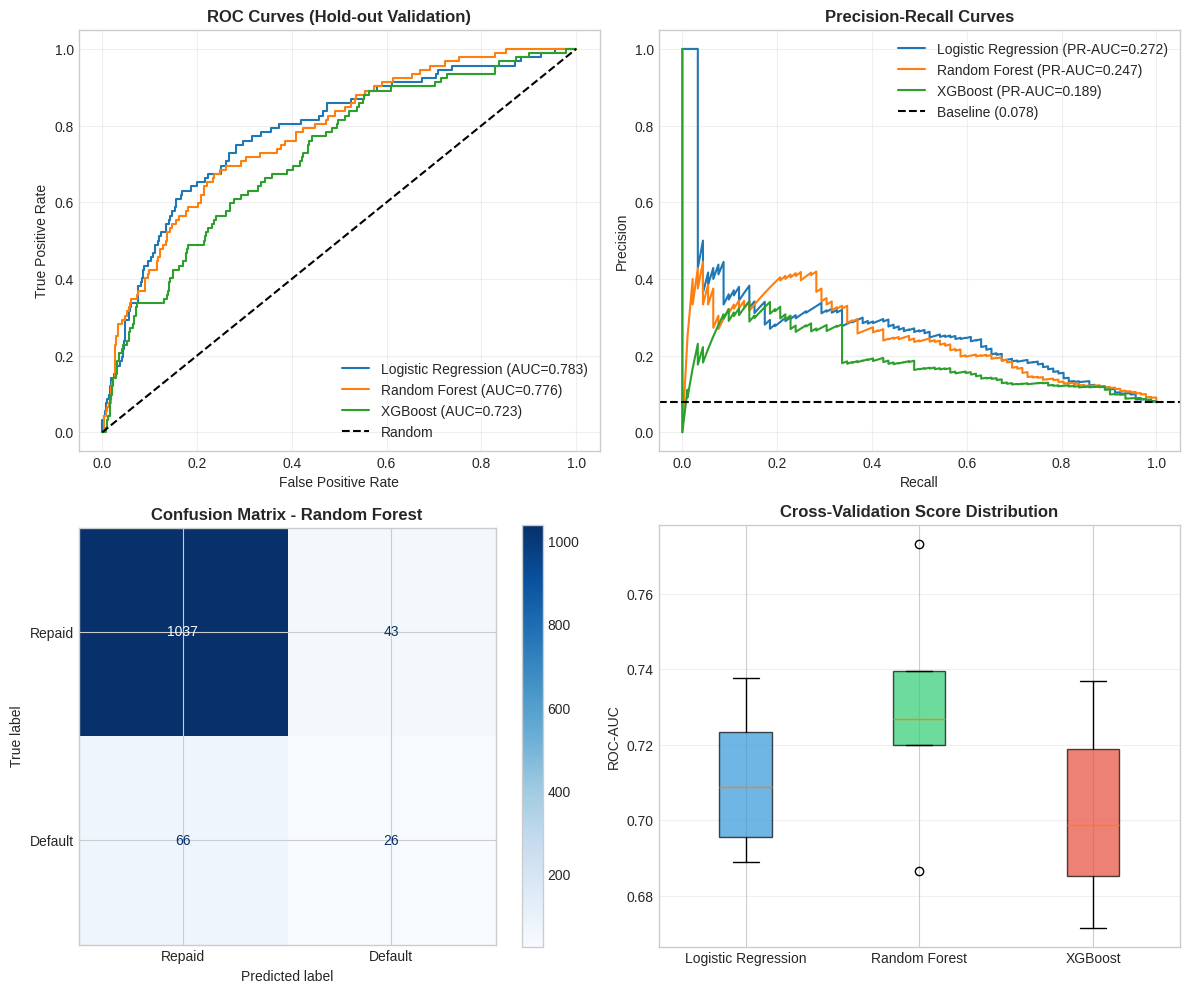


✅ PHASE 5 COMPLETE

EVALUATION SUMMARY:
───────────────────
• Validation Method: 5-Fold Stratified Cross-Validation + Hold-out Set
• Primary Metric: ROC-AUC (appropriate for class imbalance)
• Secondary Metrics: PR-AUC, Precision, Recall, F1

BEST MODEL: Random Forest
─────────────────────────────
• CV ROC-AUC:    0.7291 ± 0.0281
• Val ROC-AUC:   0.7760
• Val PR-AUC:    0.2472
• Val Precision: 0.3768
• Val Recall:    0.2826
• Val F1:        0.3230




In [51]:
# ============================================================
# PHASE 5: MODEL DEVELOPMENT
# ============================================================

print("="*70)
print("PHASE 5: MODEL DEVELOPMENT")
print("="*70)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, average_precision_score, make_scorer)
import warnings
warnings.filterwarnings('ignore')

print("""
📋 EVALUATION STRATEGY:
• Primary Metric: ROC-AUC (handles class imbalance better than accuracy)
• Secondary Metrics: Precision, Recall, F1-Score, PR-AUC
• Validation: 5-Fold Stratified Cross-Validation
• Final Evaluation: Hold-out validation set
""")

# --------------------------------------------------------------
# Step 5.1: Define Models
# --------------------------------------------------------------
print("\n📌 STEP 5.1: DEFINE MODELS")
print("-"*50)

models = {
    'Logistic Regression': LogisticRegression(
        random_state=42,
        max_iter=1000,
        class_weight='balanced'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        scale_pos_weight=class_weight_dict[1]/class_weight_dict[0],
        use_label_encoder=False,
        eval_metric='auc',
        verbosity=0
    )
}

print(f"Models: {list(models.keys())}")
print("""
Model Selection Rationale:
• Logistic Regression: Interpretable baseline, coefficients explain impact
• Random Forest: Non-linear, feature importance, robust
• XGBoost: High performance, handles imbalance well
""")

# --------------------------------------------------------------
# Step 5.2: Cross-Validation Setup
# --------------------------------------------------------------
print("\n📌 STEP 5.2: CROSS-VALIDATION SETUP")
print("-"*50)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define scoring metrics
scoring = {
    'roc_auc': 'roc_auc',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'pr_auc': 'average_precision'
}

print(f"Cross-Validation: 5-Fold Stratified")
print(f"Metrics: ROC-AUC (primary), Precision, Recall, F1, PR-AUC (secondary)")

# --------------------------------------------------------------
# Step 5.3: Train with Cross-Validation
# --------------------------------------------------------------
print("\n📌 STEP 5.3: CROSS-VALIDATION RESULTS")
print("-"*50)

cv_results = {}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"Model: {name}")
    print('='*50)

    # Cross-validation
    scores = cross_validate(
        model, X_train_scaled, y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    cv_results[name] = {
        'cv_roc_auc_mean': scores['test_roc_auc'].mean(),
        'cv_roc_auc_std': scores['test_roc_auc'].std(),
        'cv_precision_mean': scores['test_precision'].mean(),
        'cv_recall_mean': scores['test_recall'].mean(),
        'cv_f1_mean': scores['test_f1'].mean(),
        'cv_pr_auc_mean': scores['test_pr_auc'].mean(),
        'cv_scores': scores
    }

    print(f"\n5-Fold CV Results:")
    print(f"   ROC-AUC:   {scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}")
    print(f"   PR-AUC:    {scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}")
    print(f"   Precision: {scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}")
    print(f"   Recall:    {scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}")
    print(f"   F1-Score:  {scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}")

# --------------------------------------------------------------
# Step 5.4: Train Final Models & Evaluate on Hold-out Set
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 5.4: HOLD-OUT VALIDATION SET EVALUATION")
print("="*70)

results = {}

for name, model in models.items():
    # Train on full training set
    model.fit(X_train_scaled, y_train)

    # Predict on hold-out validation set
    y_val_pred = model.predict(X_val_scaled)
    y_val_proba = model.predict_proba(X_val_scaled)[:, 1]

    # Calculate metrics
    results[name] = {
        'model': model,
        'cv_roc_auc': cv_results[name]['cv_roc_auc_mean'],
        'cv_roc_auc_std': cv_results[name]['cv_roc_auc_std'],
        'val_roc_auc': roc_auc_score(y_val, y_val_proba),
        'val_pr_auc': average_precision_score(y_val, y_val_proba),
        'val_precision': precision_score(y_val, y_val_pred),
        'val_recall': recall_score(y_val, y_val_pred),
        'val_f1': f1_score(y_val, y_val_pred),
        'y_val_pred': y_val_pred,
        'y_val_proba': y_val_proba
    }

# --------------------------------------------------------------
# Step 5.5: Model Comparison Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 5.5: MODEL COMPARISON SUMMARY")
print("="*70)

comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'CV ROC-AUC': [f"{results[m]['cv_roc_auc']:.4f} ± {results[m]['cv_roc_auc_std']:.4f}" for m in results],
    'Val ROC-AUC': [results[m]['val_roc_auc'] for m in results],
    'Val PR-AUC': [results[m]['val_pr_auc'] for m in results],
    'Precision': [results[m]['val_precision'] for m in results],
    'Recall': [results[m]['val_recall'] for m in results],
    'F1': [results[m]['val_f1'] for m in results]
}).round(4)

print("\n📊 FULL COMPARISON:")
print(comparison_df.to_string(index=False))

# Best model by CV ROC-AUC
best_model_name = max(results, key=lambda x: results[x]['cv_roc_auc'])
best_model = results[best_model_name]['model']

print(f"\n🏆 BEST MODEL: {best_model_name}")
print(f"   CV ROC-AUC:  {results[best_model_name]['cv_roc_auc']:.4f} ± {results[best_model_name]['cv_roc_auc_std']:.4f}")
print(f"   Val ROC-AUC: {results[best_model_name]['val_roc_auc']:.4f}")

# --------------------------------------------------------------
# Step 5.6: Visualize Results
# --------------------------------------------------------------
print("\n📌 STEP 5.6: VISUALIZE RESULTS")
print("-"*50)

from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ROC Curves
ax1 = axes[0, 0]
for name in results:
    fpr, tpr, _ = roc_curve(y_val, results[name]['y_val_proba'])
    ax1.plot(fpr, tpr, label=f"{name} (AUC={results[name]['val_roc_auc']:.3f})")
ax1.plot([0, 1], [0, 1], 'k--', label='Random')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves (Hold-out Validation)', fontweight='bold')
ax1.legend(loc='lower right')
ax1.grid(True, alpha=0.3)

# Precision-Recall Curves
ax2 = axes[0, 1]
for name in results:
    precision, recall, _ = precision_recall_curve(y_val, results[name]['y_val_proba'])
    ax2.plot(recall, precision, label=f"{name} (PR-AUC={results[name]['val_pr_auc']:.3f})")
ax2.axhline(y=y_val.mean(), color='k', linestyle='--', label=f'Baseline ({y_val.mean():.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curves', fontweight='bold')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

# Confusion Matrix for Best Model
ax3 = axes[1, 0]
cm = confusion_matrix(y_val, results[best_model_name]['y_val_pred'])
ConfusionMatrixDisplay(cm, display_labels=['Repaid', 'Default']).plot(ax=ax3, cmap='Blues')
ax3.set_title(f'Confusion Matrix - {best_model_name}', fontweight='bold')

# CV Score Distribution
ax4 = axes[1, 1]
cv_scores_data = [cv_results[m]['cv_scores']['test_roc_auc'] for m in cv_results]
bp = ax4.boxplot(cv_scores_data, labels=list(cv_results.keys()), patch_artist=True)
colors = ['#3498db', '#2ecc71', '#e74c3c']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax4.set_ylabel('ROC-AUC')
ax4.set_title('Cross-Validation Score Distribution', fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('phase5_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ PHASE 5 COMPLETE")
print("="*70)

print(f"""
EVALUATION SUMMARY:
───────────────────
• Validation Method: 5-Fold Stratified Cross-Validation + Hold-out Set
• Primary Metric: ROC-AUC (appropriate for class imbalance)
• Secondary Metrics: PR-AUC, Precision, Recall, F1

BEST MODEL: {best_model_name}
─────────────────────────────
• CV ROC-AUC:    {results[best_model_name]['cv_roc_auc']:.4f} ± {results[best_model_name]['cv_roc_auc_std']:.4f}
• Val ROC-AUC:   {results[best_model_name]['val_roc_auc']:.4f}
• Val PR-AUC:    {results[best_model_name]['val_pr_auc']:.4f}
• Val Precision: {results[best_model_name]['val_precision']:.4f}
• Val Recall:    {results[best_model_name]['val_recall']:.4f}
• Val F1:        {results[best_model_name]['val_f1']:.4f}

""")

**HYPERPARAMETER TUNING (ADDING GRADIENT BOOSTING & LIGHT GBM AS WELL)**


📌 STEP 6.1: DEFINE MODELS & PARAMETERS
--------------------------------------------------
Logistic Regression: 3 combinations
Random Forest: 4 combinations
Gradient Boosting: 8 combinations
XGBoost: 8 combinations
LightGBM: 8 combinations

📌 STEP 6.2: TUNING ALL MODELS (3-Fold CV)
--------------------------------------------------

Tuning Logistic Regression... Done (6.6s) | CV: 0.7191 | Val: 0.7825

Tuning Random Forest... Done (22.6s) | CV: 0.7334 | Val: 0.7721

Tuning Gradient Boosting... Done (120.3s) | CV: 0.7199 | Val: 0.7722

Tuning XGBoost... Done (9.9s) | CV: 0.7056 | Val: 0.7446

Tuning LightGBM... Done (10.4s) | CV: 0.7062 | Val: 0.7363

STEP 6.3: MODEL COMPARISON

📊 ALL MODELS RANKED:
              Model  CV ROC-AUC  Val ROC-AUC  Val PR-AUC  Precision  Recall     F1
Logistic Regression      0.7191       0.7825      0.2713     0.1759  0.7609 0.2857
  Gradient Boosting      0.7199       0.7722      0.2366     0.1429  0.0109 0.0202
      Random Forest      0.7334       0.7721

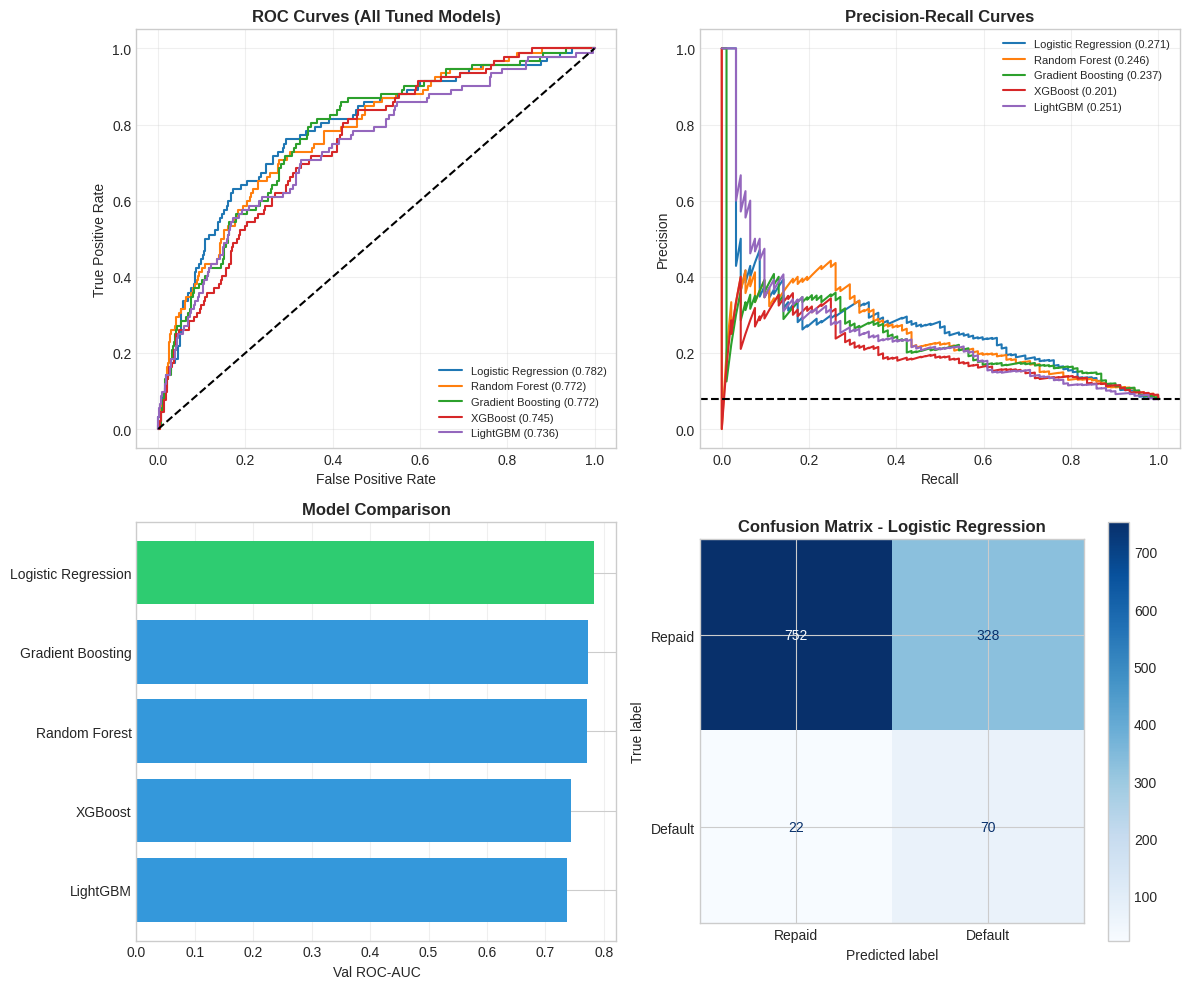


✅ PHASE 6 COMPLETE

MODELS EVALUATED: 5
• Logistic Regression (interpretable baseline)
• Random Forest (feature importance)
• Gradient Boosting (sequential boosting)
• XGBoost (optimized boosting)
• LightGBM (fast boosting)

BEST MODEL: Logistic Regression
• Val ROC-AUC: 0.7825
• Val Recall:  0.7609
• Params: {'C': 0.1}
      


In [53]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, average_precision_score
import time
import warnings
warnings.filterwarnings('ignore')

# --------------------------------------------------------------
# Step 6.1: Define Models and Parameter Grids
# --------------------------------------------------------------
print("\n📌 STEP 6.1: DEFINE MODELS & PARAMETERS")
print("-"*50)

models_config = {
    'Logistic Regression': {
        'model': LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced'),
        'params': {'C': [0.1, 1, 10]}
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
        'params': {'n_estimators': [100, 200], 'max_depth': [10, 15]}
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {'n_estimators': [100, 150], 'max_depth': [3, 5], 'learning_rate': [0.1, 0.2]}
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, scale_pos_weight=class_weight_dict[1]/class_weight_dict[0],
                               use_label_encoder=False, eval_metric='auc', verbosity=0),
        'params': {'n_estimators': [100, 150], 'max_depth': [3, 5], 'learning_rate': [0.1, 0.2]}
    },
    'LightGBM': {
        'model': LGBMClassifier(random_state=42, class_weight='balanced', verbosity=-1),
        'params': {'n_estimators': [100, 150], 'max_depth': [5, 10], 'learning_rate': [0.1, 0.2]}
    }
}

for name, config in models_config.items():
    total = 1
    for v in config['params'].values():
        total *= len(v)
    print(f"{name}: {total} combinations")

# --------------------------------------------------------------
# Step 6.2: Tune All Models
# --------------------------------------------------------------
print("\n📌 STEP 6.2: TUNING ALL MODELS (3-Fold CV)")
print("-"*50)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
tuned_results = {}

for name, config in models_config.items():
    print(f"\nTuning {name}...", end=" ")
    start = time.time()

    grid = GridSearchCV(
        config['model'],
        config['params'],
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)

    # Evaluate on validation set
    y_val_pred = grid.best_estimator_.predict(X_val_scaled)
    y_val_proba = grid.best_estimator_.predict_proba(X_val_scaled)[:, 1]

    tuned_results[name] = {
        'model': grid.best_estimator_,
        'best_params': grid.best_params_,
        'cv_roc_auc': grid.best_score_,
        'val_roc_auc': roc_auc_score(y_val, y_val_proba),
        'val_pr_auc': average_precision_score(y_val, y_val_proba),
        'val_precision': precision_score(y_val, y_val_pred),
        'val_recall': recall_score(y_val, y_val_pred),
        'val_f1': f1_score(y_val, y_val_pred),
        'y_val_pred': y_val_pred,
        'y_val_proba': y_val_proba
    }

    print(f"Done ({time.time()-start:.1f}s) | CV: {grid.best_score_:.4f} | Val: {tuned_results[name]['val_roc_auc']:.4f}")

# --------------------------------------------------------------
# Step 6.3: Compare All Models
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 6.3: MODEL COMPARISON")
print("="*70)

tuned_df = pd.DataFrame({
    'Model': list(tuned_results.keys()),
    'CV ROC-AUC': [tuned_results[m]['cv_roc_auc'] for m in tuned_results],
    'Val ROC-AUC': [tuned_results[m]['val_roc_auc'] for m in tuned_results],
    'Val PR-AUC': [tuned_results[m]['val_pr_auc'] for m in tuned_results],
    'Precision': [tuned_results[m]['val_precision'] for m in tuned_results],
    'Recall': [tuned_results[m]['val_recall'] for m in tuned_results],
    'F1': [tuned_results[m]['val_f1'] for m in tuned_results]
}).round(4)

tuned_df = tuned_df.sort_values('Val ROC-AUC', ascending=False)
print("\n📊 ALL MODELS RANKED:")
print(tuned_df.to_string(index=False))

# Best model
best_tuned_name = tuned_df.iloc[0]['Model']
best_tuned_model = tuned_results[best_tuned_name]['model']

print(f"\n🏆 BEST MODEL: {best_tuned_name}")
print(f"   Best Params: {tuned_results[best_tuned_name]['best_params']}")
print(f"   Val ROC-AUC: {tuned_results[best_tuned_name]['val_roc_auc']:.4f}")
print(f"   Val Recall:  {tuned_results[best_tuned_name]['val_recall']:.4f}")

# --------------------------------------------------------------
# Step 6.4: Visualize Results
# --------------------------------------------------------------
print("\n📌 STEP 6.4: VISUALIZE RESULTS")
print("-"*50)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ROC Curves
ax1 = axes[0, 0]
for name in tuned_results:
    fpr, tpr, _ = roc_curve(y_val, tuned_results[name]['y_val_proba'])
    ax1.plot(fpr, tpr, label=f"{name} ({tuned_results[name]['val_roc_auc']:.3f})")
ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curves (All Tuned Models)', fontweight='bold')
ax1.legend(loc='lower right', fontsize=8)
ax1.grid(True, alpha=0.3)

# PR Curves
ax2 = axes[0, 1]
for name in tuned_results:
    prec, rec, _ = precision_recall_curve(y_val, tuned_results[name]['y_val_proba'])
    ax2.plot(rec, prec, label=f"{name} ({tuned_results[name]['val_pr_auc']:.3f})")
ax2.axhline(y=y_val.mean(), color='k', linestyle='--')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curves', fontweight='bold')
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, alpha=0.3)

# Bar Chart - ROC-AUC
ax3 = axes[1, 0]
models_sorted = tuned_df['Model'].tolist()
aucs = [tuned_results[m]['val_roc_auc'] for m in models_sorted]
colors = ['#2ecc71' if m == best_tuned_name else '#3498db' for m in models_sorted]
ax3.barh(models_sorted[::-1], aucs[::-1], color=colors[::-1])
ax3.set_xlabel('Val ROC-AUC')
ax3.set_title('Model Comparison', fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# Confusion Matrix - Best Model
ax4 = axes[1, 1]
cm = confusion_matrix(y_val, tuned_results[best_tuned_name]['y_val_pred'])
ConfusionMatrixDisplay(cm, display_labels=['Repaid', 'Default']).plot(ax=ax4, cmap='Blues')
ax4.set_title(f'Confusion Matrix - {best_tuned_name}', fontweight='bold')

plt.tight_layout()
plt.savefig('phase6_all_models.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("✅ PHASE 6 COMPLETE")
print("="*70)

print(f"""
MODELS EVALUATED: {len(tuned_results)}
• Logistic Regression (interpretable baseline)
• Random Forest (feature importance)
• Gradient Boosting (sequential boosting)
• XGBoost (optimized boosting)
• LightGBM (fast boosting)

BEST MODEL: {best_tuned_name}
• Val ROC-AUC: {tuned_results[best_tuned_name]['val_roc_auc']:.4f}
• Val Recall:  {tuned_results[best_tuned_name]['val_recall']:.4f}
• Params: {tuned_results[best_tuned_name]['best_params']}
      """)

**MODEL EXPLAINABILITY (XAI)**

Explainability is crucial for credit decisions because:
1. Legal requirement: Applicants have right to know why they were denied
2. Trust: Stakeholders need to understand model decisions
3. Debugging: Identify if model uses features inappropriately

*EXPLAINABILITY METHODS APPLIED:*

• Logistic Regression Coefficients (direct interpretation)

• Random Forest Feature Importance

• SHAP Values (global and local explanations)


STEP 7.1: LOGISTIC REGRESSION COEFFICIENTS

📊 TOP 15 MOST INFLUENTIAL FEATURES:
                 Feature  Coefficient                 Impact
              AMT_CREDIT     0.354707 Increases Default Risk
     NAME_EDUCATION_TYPE     0.276480 Increases Default Risk
        LOAN_TERM_MONTHS    -0.264833 Decreases Default Risk
             CODE_GENDER     0.262216 Increases Default Risk
      CREDIT_GOODS_RATIO     0.236817 Increases Default Risk
            EXT_SOURCE_3    -0.234317 Decreases Default Risk
DEF_60_CNT_SOCIAL_CIRCLE     0.228661 Increases Default Risk
         EXT_SOURCE_MEAN    -0.215776 Decreases Default Risk
             AMT_ANNUITY    -0.193196 Decreases Default Risk
        AMT_INCOME_TOTAL    -0.179904 Decreases Default Risk
OBS_60_CNT_SOCIAL_CIRCLE     0.169653 Increases Default Risk
OBS_30_CNT_SOCIAL_CIRCLE    -0.168613 Decreases Default Risk
         CNT_FAM_MEMBERS    -0.163425 Decreases Default Risk
         FLAG_DOCUMENT_3     0.155059 Increases Default Risk
    

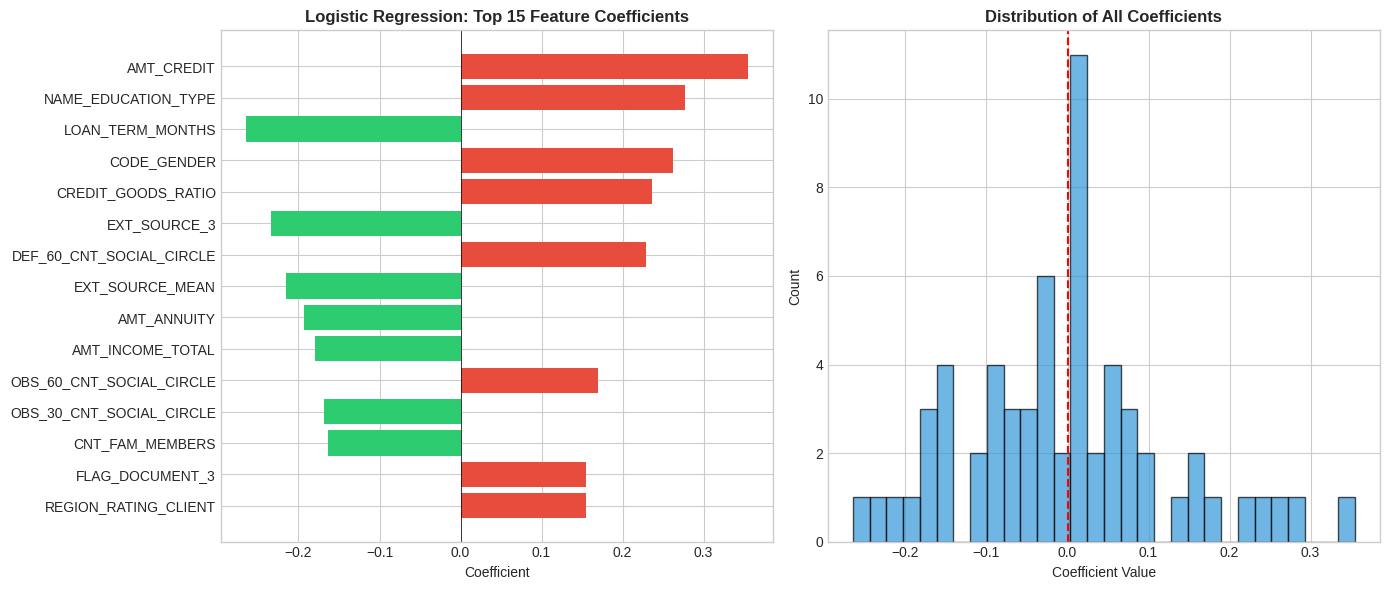


STEP 7.2: RANDOM FOREST FEATURE IMPORTANCE

📊 TOP 15 IMPORTANT FEATURES (Random Forest):
               Feature  Importance
       EXT_SOURCE_MEAN    0.073571
       EXT_SOURCE_PROD    0.067479
        EXT_SOURCE_MIN    0.065204
          EXT_SOURCE_2    0.048825
          EXT_SOURCE_3    0.043923
    CREDIT_GOODS_RATIO    0.035861
             AGE_YEARS    0.034431
DAYS_LAST_PHONE_CHANGE    0.032444
            DAYS_BIRTH    0.032231
      LOAN_TERM_MONTHS    0.031817
           AMT_ANNUITY    0.028122
     DAYS_REGISTRATION    0.028014
      EMPLOYMENT_YEARS    0.027681
       DAYS_ID_PUBLISH    0.026461
            AMT_CREDIT    0.025790

STEP 7.3: SHAP ANALYSIS
Computing SHAP values for 500 samples...
✅ SHAP values computed


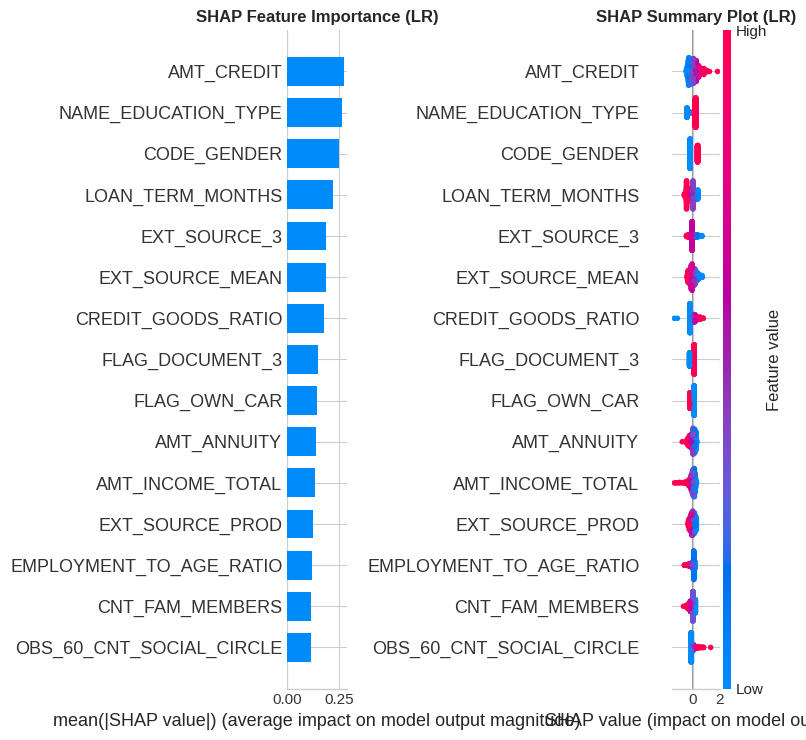


STEP 7.4: INDIVIDUAL PREDICTION EXPLANATIONS

📋 RAI REQUIREMENT: 
When denying credit, we must explain WHY to the applicant.
Let's show example explanations for individual predictions.


📌 EXAMPLE 1: Applicant Predicted to DEFAULT
--------------------------------------------------
Prediction: DEFAULT (1)
Probability of Default: 57.08%

Top 5 reasons for this prediction:
   • LOAN_TERM_MONTHS: ↓ Decreases default risk (SHAP: -0.4586)
   • EXT_SOURCE_MEAN: ↑ Increases default risk (SHAP: 0.4143)
   • CREDIT_INCOME_RATIO: ↓ Decreases default risk (SHAP: -0.3179)
   • REGION_RATING_CLIENT: ↑ Increases default risk (SHAP: 0.3050)
   • EXT_SOURCE_PROD: ↑ Increases default risk (SHAP: 0.2795)

📌 EXAMPLE 2: Applicant Predicted to REPAY
--------------------------------------------------
Prediction: REPAY (0)
Probability of Default: 35.04%

Top 5 reasons for this prediction:
   • AMT_CREDIT: ↑ Increases default risk (SHAP: 0.8424)
   • LOAN_TERM_MONTHS: ↓ Decreases default risk (SHAP: -0.4551)


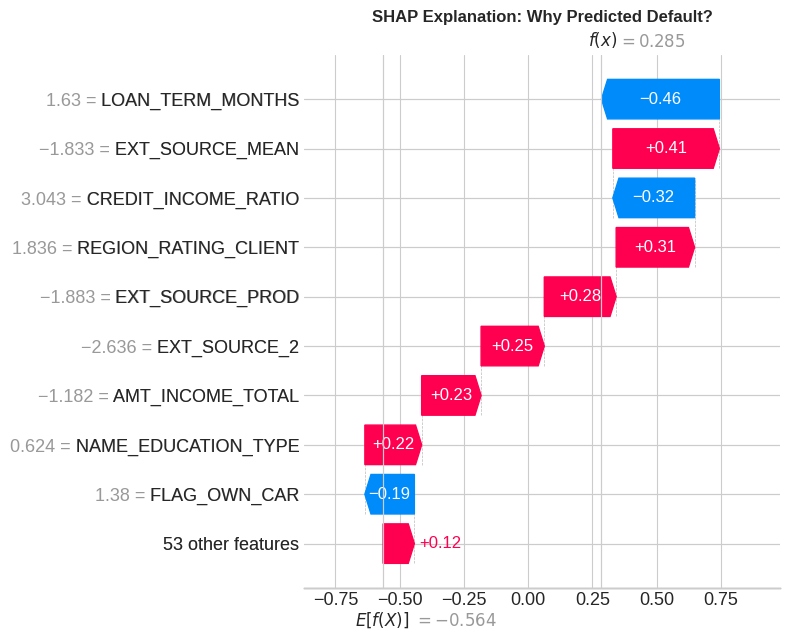


STEP 7.5: RAI CHECK - PROTECTED ATTRIBUTES

📊 Are protected attributes driving predictions?
--------------------------------------------------
   ⚠️  CODE_GENDER: Rank 4/20, Coefficient: 0.2622
   ✅ AGE_YEARS: Not in top 20 features
   ✅ NAME_FAMILY_STATUS: Not in top 20 features
   ⚠️  NAME_EDUCATION_TYPE: Rank 2/20, Coefficient: 0.2765
   ✅ NAME_INCOME_TYPE: Not in top 20 features


In [55]:
# --------------------------------------------------------------
# Step 7.1: Logistic Regression Coefficients
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 7.1: LOGISTIC REGRESSION COEFFICIENTS")
print("="*70)

# Get the best logistic regression model
lr_model = tuned_results['Logistic Regression']['model']

# Get coefficients
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_model.coef_[0]
})
coef_df['Abs_Coefficient'] = abs(coef_df['Coefficient'])
coef_df['Impact'] = coef_df['Coefficient'].apply(lambda x: 'Increases Default Risk' if x > 0 else 'Decreases Default Risk')
coef_df = coef_df.sort_values('Abs_Coefficient', ascending=False)

print("\n📊 TOP 15 MOST INFLUENTIAL FEATURES:")
print(coef_df.head(15)[['Feature', 'Coefficient', 'Impact']].to_string(index=False))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Top 15 coefficients
top_15 = coef_df.head(15)
colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in top_15['Coefficient']]
axes[0].barh(top_15['Feature'], top_15['Coefficient'], color=colors)
axes[0].set_xlabel('Coefficient')
axes[0].set_title('Logistic Regression: Top 15 Feature Coefficients', fontweight='bold')
axes[0].axvline(x=0, color='black', linewidth=0.5)
axes[0].invert_yaxis()

# All coefficients distribution
axes[1].hist(coef_df['Coefficient'], bins=30, color='#3498db', edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Coefficient Value')
axes[1].set_ylabel('Count')
axes[1].set_title('Distribution of All Coefficients', fontweight='bold')
axes[1].axvline(x=0, color='red', linestyle='--')

plt.tight_layout()
plt.savefig('phase7_lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Step 7.2: Random Forest Feature Importance
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 7.2: RANDOM FOREST FEATURE IMPORTANCE")
print("="*70)

rf_model = tuned_results['Random Forest']['model']

rf_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n📊 TOP 15 IMPORTANT FEATURES (Random Forest):")
print(rf_importance.head(15).to_string(index=False))

# --------------------------------------------------------------
# Step 7.3: SHAP Analysis (using best model)
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 7.3: SHAP ANALYSIS")
print("="*70)

import shap

# Use a sample for faster computation
sample_size = 500
X_sample = X_val_scaled.iloc[:sample_size]

print(f"Computing SHAP values for {sample_size} samples...")

# SHAP for Logistic Regression
explainer_lr = shap.LinearExplainer(lr_model, X_train_scaled)
shap_values_lr = explainer_lr.shap_values(X_sample)

print("✅ SHAP values computed")

# SHAP Summary Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Summary plot (bar)
plt.sca(axes[0])
shap.summary_plot(shap_values_lr, X_sample, plot_type="bar", show=False, max_display=15)
axes[0].set_title('SHAP Feature Importance (LR)', fontweight='bold')

# Summary plot (dot)
plt.sca(axes[1])
shap.summary_plot(shap_values_lr, X_sample, show=False, max_display=15)
axes[1].set_title('SHAP Summary Plot (LR)', fontweight='bold')

plt.tight_layout()
plt.savefig('phase7_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Step 7.4: Individual Prediction Explanations
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 7.4: INDIVIDUAL PREDICTION EXPLANATIONS")
print("="*70)

print("""
📋 RAI REQUIREMENT:
When denying credit, we must explain WHY to the applicant.
Let's show example explanations for individual predictions.
""")

# Find one default prediction and one repaid prediction
default_indices = np.where(tuned_results['Logistic Regression']['y_val_pred'] == 1)[0]
repaid_indices = np.where(tuned_results['Logistic Regression']['y_val_pred'] == 0)[0]

# Example 1: Predicted Default
idx_default = default_indices[0]
print(f"\n📌 EXAMPLE 1: Applicant Predicted to DEFAULT")
print("-"*50)
print(f"Prediction: DEFAULT (1)")
print(f"Probability of Default: {tuned_results['Logistic Regression']['y_val_proba'][idx_default]:.2%}")

# Top contributing features for this prediction
if idx_default < len(shap_values_lr):
    individual_shap = pd.DataFrame({
        'Feature': feature_cols,
        'SHAP Value': shap_values_lr[idx_default]
    }).sort_values('SHAP Value', key=abs, ascending=False)

    print("\nTop 5 reasons for this prediction:")
    for i, row in individual_shap.head(5).iterrows():
        direction = "↑ Increases" if row['SHAP Value'] > 0 else "↓ Decreases"
        print(f"   • {row['Feature']}: {direction} default risk (SHAP: {row['SHAP Value']:.4f})")

# Example 2: Predicted Repaid
idx_repaid = repaid_indices[0]
print(f"\n📌 EXAMPLE 2: Applicant Predicted to REPAY")
print("-"*50)
print(f"Prediction: REPAY (0)")
print(f"Probability of Default: {tuned_results['Logistic Regression']['y_val_proba'][idx_repaid]:.2%}")

if idx_repaid < len(shap_values_lr):
    individual_shap = pd.DataFrame({
        'Feature': feature_cols,
        'SHAP Value': shap_values_lr[idx_repaid]
    }).sort_values('SHAP Value', key=abs, ascending=False)

    print("\nTop 5 reasons for this prediction:")
    for i, row in individual_shap.head(5).iterrows():
        direction = "↑ Increases" if row['SHAP Value'] > 0 else "↓ Decreases"
        print(f"   • {row['Feature']}: {direction} default risk (SHAP: {row['SHAP Value']:.4f})")

# Waterfall plot for individual prediction
print("\n📊 SHAP Waterfall Plot (Individual Explanation):")
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
shap.plots.waterfall(shap.Explanation(values=shap_values_lr[idx_default],
                                        base_values=explainer_lr.expected_value,
                                        data=X_sample.iloc[idx_default],
                                        feature_names=feature_cols),
                     max_display=10, show=False)
plt.title('SHAP Explanation: Why Predicted Default?', fontweight='bold')
plt.tight_layout()
plt.savefig('phase7_shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Step 7.5: RAI Check - Protected Attributes in Top Features
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 7.5: RAI CHECK - PROTECTED ATTRIBUTES")
print("="*70)

protected = ['CODE_GENDER', 'AGE_YEARS', 'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']

print("\n📊 Are protected attributes driving predictions?")
print("-"*50)

top_20_features = coef_df.head(20)['Feature'].tolist()

for attr in protected:
    if attr in top_20_features:
        rank = top_20_features.index(attr) + 1
        coef = coef_df[coef_df['Feature'] == attr]['Coefficient'].values[0]
        print(f"   ⚠️  {attr}: Rank {rank}/20, Coefficient: {coef:.4f}")
    else:
        print(f"   ✅ {attr}: Not in top 20 features")



*   Gender is 4th most influential feature - model is using gender to make decisions!
*   Education is 2nd most influential - may disadvantage certain socioeconomic groups



 **LIME EXPLANATIONS & COUNTERFACTUALS EXPLANATIONS**

STEP 7.2b: LIME (Local Interpretable Model-agnostic Explanations)

📌 LIME Explanation: Applicant Predicted to DEFAULT
--------------------------------------------------
Prediction: DEFAULT
Probability: 89.35%

Top factors (LIME):
   • DEF_60_CNT_SOCIAL_CIRCLE > -0.28: ↑ Default (0.1559)
   • -0.93 < NAME_EDUCATION_TYPE <= 0.62: ↑ Default (0.1103)
   • CREDIT_GOODS_RATIO > 0.61: ↑ Default (0.0937)
   • EXT_SOURCE_3 <= -0.55: ↑ Default (0.0918)
   • REGION_RATING_CLIENT > -0.11: ↑ Default (0.0902)
   • LIVE_REGION_NOT_WORK_REGION <= -0.20: ↓ Repay (-0.0899)
   • EXT_SOURCE_MEAN <= -0.65: ↑ Default (0.0865)
   • AMT_REQ_CREDIT_BUREAU_WEEK <= -0.17: ↑ Default (0.0807)
   • -0.72 < CODE_GENDER <= 1.39: ↑ Default (0.0698)
   • REG_REGION_NOT_WORK_REGION <= -0.23: ↑ Default (0.0690)

📌 LIME Explanation: Applicant Predicted to REPAY
--------------------------------------------------
Prediction: REPAY
Probability of Default: 2.82%

Top factors (LIME):
   • AMT_CREDIT > 0.54: ↑ Default (0.1547)


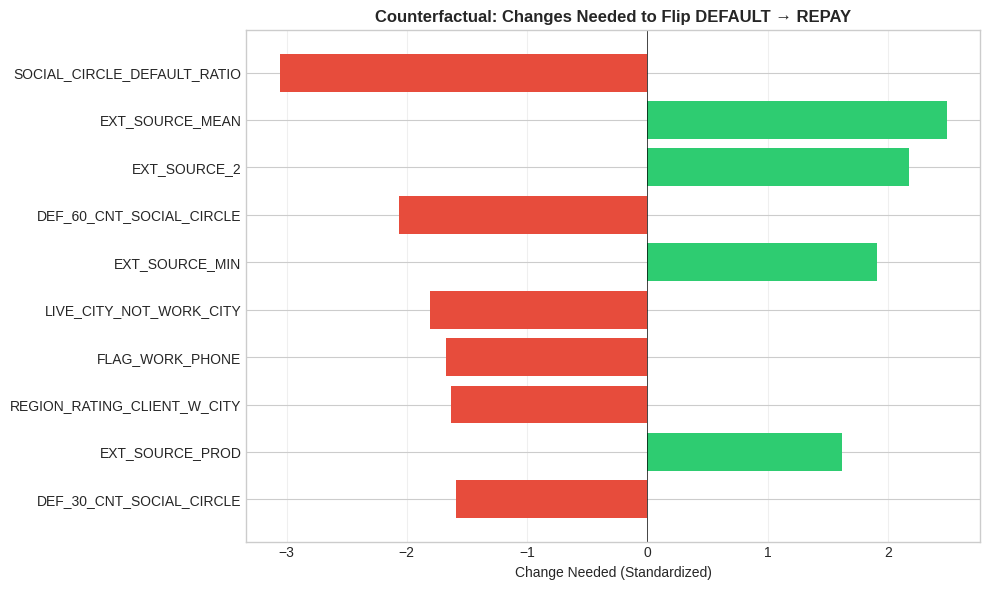

In [59]:
!pip install lime -q

print("="*70)
print("STEP 7.2b: LIME (Local Interpretable Model-agnostic Explanations)")
print("="*70)

import lime
import lime.lime_tabular

# Create LIME explainer
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train_scaled),
    feature_names=feature_cols,
    class_names=['Repaid', 'Default'],
    mode='classification',
    random_state=42
)

# Get best model
best_model = tuned_results['Logistic Regression']['model']

# Explain a DEFAULT prediction
print("\n📌 LIME Explanation: Applicant Predicted to DEFAULT")
print("-"*50)

default_idx = np.where(y_val_pred == 1)[0][0]
lime_exp_default = lime_explainer.explain_instance(
    X_val_scaled.iloc[default_idx].values,
    best_model.predict_proba,
    num_features=10
)

print(f"Prediction: DEFAULT")
print(f"Probability: {y_val_proba[default_idx]:.2%}")
print("\nTop factors (LIME):")
for feature, weight in lime_exp_default.as_list()[:10]:
    direction = "↑ Default" if weight > 0 else "↓ Repay"
    print(f"   • {feature}: {direction} ({weight:.4f})")

# Explain a REPAID prediction
print("\n📌 LIME Explanation: Applicant Predicted to REPAY")
print("-"*50)

repaid_idx = np.where(y_val_pred == 0)[0][0]
lime_exp_repaid = lime_explainer.explain_instance(
    X_val_scaled.iloc[repaid_idx].values,
    best_model.predict_proba,
    num_features=10
)

print(f"Prediction: REPAY")
print(f"Probability of Default: {y_val_proba[repaid_idx]:.2%}")
print("\nTop factors (LIME):")
for feature, weight in lime_exp_repaid.as_list()[:10]:
    direction = "↑ Default" if weight > 0 else "↓ Repay"
    print(f"   • {feature}: {direction} ({weight:.4f})")

# ============================================================
# STEP 7.3: COUNTERFACTUAL EXPLANATIONS
# ============================================================

print("\n" + "="*70)
print("STEP 7.3: COUNTERFACTUAL EXPLANATIONS")
print("="*70)

print("""
📋 RAI CONTEXT:
Counterfactuals answer: "What minimal changes would flip the prediction?"
This helps applicants understand what they can do to get approved.
""")

def find_counterfactual(model, instance, feature_names, X_train, desired_class=0, max_iterations=1000):
    """Find minimal changes to flip prediction."""

    instance = instance.copy()
    original_pred = model.predict([instance])[0]

    if original_pred == desired_class:
        return None, "Already predicted as desired class"

    # Get mean values for desired class
    desired_class_mask = y_train == desired_class
    desired_mean = X_train[desired_class_mask].mean()

    # Track changes
    changes = {}
    cf_instance = instance.copy()

    # Gradually move toward desired class mean
    for step in range(1, max_iterations + 1):
        alpha = step / max_iterations
        cf_instance = instance * (1 - alpha) + desired_mean.values * alpha

        new_pred = model.predict([cf_instance])[0]

        if new_pred == desired_class:
            # Found counterfactual - identify changes
            for i, feat in enumerate(feature_names):
                if abs(cf_instance[i] - instance[i]) > 0.01:
                    changes[feat] = {
                        'original': instance[i],
                        'counterfactual': cf_instance[i],
                        'change': cf_instance[i] - instance[i]
                    }
            return cf_instance, changes

    return None, "Could not find counterfactual"

# Find counterfactual for a DEFAULT prediction
print("\n📌 COUNTERFACTUAL: How to change DEFAULT → REPAY?")
print("-"*50)

default_instance = X_val_scaled.iloc[default_idx].values
cf_instance, changes = find_counterfactual(
    best_model,
    default_instance,
    feature_cols,
    X_train_scaled
)

if isinstance(changes, dict) and len(changes) > 0:
    print(f"\nOriginal Prediction: DEFAULT ({y_val_proba[default_idx]:.2%} default probability)")
    new_proba = best_model.predict_proba([cf_instance])[0][1]
    print(f"Counterfactual Prediction: REPAY ({new_proba:.2%} default probability)")

    print(f"\n📋 MINIMAL CHANGES NEEDED TO GET APPROVED:")
    print("-"*50)

    sorted_changes = sorted(changes.items(), key=lambda x: abs(x[1]['change']), reverse=True)

    for feat, vals in sorted_changes[:10]:
        direction = "↑ Increase" if vals['change'] > 0 else "↓ Decrease"
        print(f"   • {feat}: {direction} by {abs(vals['change']):.3f}")
else:
    print(f"   {changes}")

# Visualize Counterfactual Changes
if isinstance(changes, dict) and len(changes) > 0:
    print("\n📊 Counterfactual Changes Visualization:")

    fig, ax = plt.subplots(figsize=(10, 6))

    sorted_changes = sorted(changes.items(), key=lambda x: abs(x[1]['change']), reverse=True)[:10]
    features = [x[0] for x in sorted_changes]
    change_vals = [x[1]['change'] for x in sorted_changes]

    colors = ['#2ecc71' if c > 0 else '#e74c3c' for c in change_vals]

    ax.barh(features[::-1], change_vals[::-1], color=colors[::-1])
    ax.set_xlabel('Change Needed (Standardized)')
    ax.set_title('Counterfactual: Changes Needed to Flip DEFAULT → REPAY', fontweight='bold')
    ax.axvline(x=0, color='black', linewidth=0.5)
    ax.grid(True, alpha=0.3, axis='x')

    plt.tight_layout()
    plt.savefig('phase7_counterfactual.png', dpi=150, bbox_inches='tight')
    plt.show()

**RAI IMPLICATIONS**

1. Model is partially explainable and mostly sensible
2. BUT protected attributes (gender, education) are too influential
3. Phase 8 will quantify fairness violations
4. May need bias mitigation before deployment

**FAIRNESS & BIAS EVALUATIONS**

PHASE 8: FAIRNESS & BIAS EVALUATION

📌 STEP 8.2: GENDER FAIRNESS
--------------------------------------------------
Gender     Count      Approval%    TPR        FPR       
----------------------------------------------------
0          758        71.77        0.6735     0.2553    
1          414        55.56        0.8605     0.3962    

Disparate Impact Ratio: 0.7741 ⚠️ FAIL

📌 STEP 8.3: AGE FAIRNESS
--------------------------------------------------
Age        Count      Approval%    TPR        FPR       
----------------------------------------------------
18-25      52         36.54        0.8000     0.6170    
26-35      268        52.61        0.9286     0.4208    
36-45      335        65.37        0.7097     0.3092    
46-55      261        74.33        0.6471     0.2295    
56-65      224        78.12        0.6364     0.1972    
65+        32         81.25        0.0000     0.1875    

Disparate Impact Ratio: 0.4497 ⚠️ FAIL

📌 STEP 8.4: EDUCATION FAIRNESS
-------------------

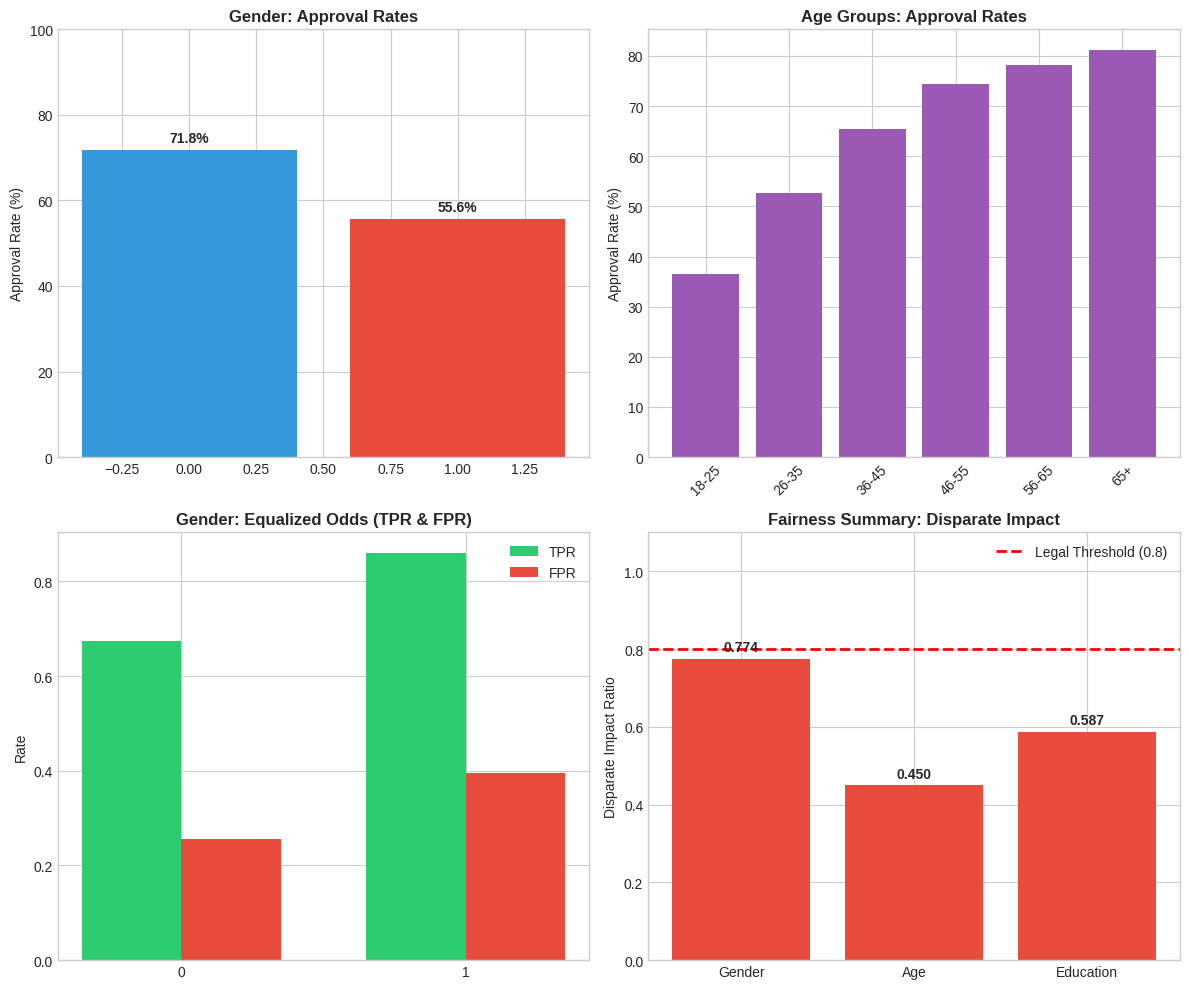


STEP 8.6: FAIRNESS SUMMARY

╔═══════════════════════════════════════════════════════════════╗
║              FAIRNESS EVALUATION RESULTS                      ║
╠═══════════════════════════════════════════════════════════════╣
║  Attribute    │ Disparate Impact │ Status                     ║
╠───────────────┼──────────────────┼────────────────────────────╣
║  Gender       │ 0.7741           │ ⚠️ FAIL (<0.8)            ║
║  Age          │ 0.4497           │ ⚠️ FAIL (<0.8)            ║
║  Education    │ 0.5874           │ ⚠️ FAIL (<0.8)            ║
╚═══════════════════════════════════════════════════════════════╝


⚠️ FAIRNESS VIOLATIONS DETECTED!

RECOMMENDED MITIGATIONS:
1. Remove protected attributes from model
2. Apply threshold adjustment per group
3. Retrain with fairness constraints
4. Use adversarial debiasing



In [60]:

print("="*70)
print("PHASE 8: FAIRNESS & BIAS EVALUATION")
print("="*70)

# Get predictions
y_val_pred = tuned_results['Logistic Regression']['y_val_pred']
y_val_proba = tuned_results['Logistic Regression']['y_val_proba']

# Get protected attributes for validation set
val_data = train.loc[X_val.index].copy()
val_data['y_true'] = y_val.values
val_data['y_pred'] = y_val_pred
val_data['y_proba'] = y_val_proba

# --------------------------------------------------------------
# Step 8.1: Fairness Metrics Function
# --------------------------------------------------------------
def calculate_fairness_metrics(data, protected_attr):
    """Calculate fairness metrics for a protected attribute"""
    results = {}
    groups = data[protected_attr].unique()

    for group in groups:
        group_data = data[data[protected_attr] == group]

        # Approval rate (predicted 0 = approved)
        approval_rate = (group_data['y_pred'] == 0).mean()

        # TPR & FPR
        tp = ((group_data['y_pred'] == 1) & (group_data['y_true'] == 1)).sum()
        fn = ((group_data['y_pred'] == 0) & (group_data['y_true'] == 1)).sum()
        fp = ((group_data['y_pred'] == 1) & (group_data['y_true'] == 0)).sum()
        tn = ((group_data['y_pred'] == 0) & (group_data['y_true'] == 0)).sum()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        results[group] = {
            'count': len(group_data),
            'approval_rate': approval_rate,
            'tpr': tpr,
            'fpr': fpr
        }
    return results

# --------------------------------------------------------------
# Step 8.2: Gender Fairness
# --------------------------------------------------------------
print("\n📌 STEP 8.2: GENDER FAIRNESS")
print("-"*50)

gender_metrics = calculate_fairness_metrics(val_data, 'CODE_GENDER')

print(f"{'Gender':<10} {'Count':<10} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*52)
for g, m in gender_metrics.items():
    print(f"{g:<10} {m['count']:<10} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

# Disparate Impact
approval_rates = [m['approval_rate'] for m in gender_metrics.values()]
gender_dir = min(approval_rates) / max(approval_rates)
print(f"\nDisparate Impact Ratio: {gender_dir:.4f} {'✅ PASS' if gender_dir >= 0.8 else '⚠️ FAIL'}")

# --------------------------------------------------------------
# Step 8.3: Age Fairness
# --------------------------------------------------------------
print("\n📌 STEP 8.3: AGE FAIRNESS")
print("-"*50)

val_data['AGE_GROUP'] = pd.cut(val_data['AGE_YEARS'],
                                bins=[0, 25, 35, 45, 55, 65, 100],
                                labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

age_metrics = calculate_fairness_metrics(val_data, 'AGE_GROUP')

print(f"{'Age':<10} {'Count':<10} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*52)
for a, m in sorted(age_metrics.items(), key=lambda x: str(x[0])):
    print(f"{a:<10} {m['count']:<10} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

approval_rates_age = [m['approval_rate'] for m in age_metrics.values()]
age_dir = min(approval_rates_age) / max(approval_rates_age)
print(f"\nDisparate Impact Ratio: {age_dir:.4f} {'✅ PASS' if age_dir >= 0.8 else '⚠️ FAIL'}")

# --------------------------------------------------------------
# Step 8.4: Education Fairness
# --------------------------------------------------------------
print("\n📌 STEP 8.4: EDUCATION FAIRNESS")
print("-"*50)

edu_metrics = calculate_fairness_metrics(val_data, 'NAME_EDUCATION_TYPE')

print(f"{'Education':<15} {'Count':<10} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*57)
for e, m in edu_metrics.items():
    print(f"{e:<15} {m['count']:<10} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

approval_rates_edu = [m['approval_rate'] for m in edu_metrics.values()]
edu_dir = min(approval_rates_edu) / max(approval_rates_edu)
print(f"\nDisparate Impact Ratio: {edu_dir:.4f} {'✅ PASS' if edu_dir >= 0.8 else '⚠️ FAIL'}")

# --------------------------------------------------------------
# Step 8.5: Visualization
# --------------------------------------------------------------
print("\n📌 STEP 8.5: FAIRNESS VISUALIZATION")
print("-"*50)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Gender Approval Rates
ax1 = axes[0, 0]
genders = list(gender_metrics.keys())
approvals = [gender_metrics[g]['approval_rate']*100 for g in genders]
colors = ['#3498db', '#e74c3c']
ax1.bar(genders, approvals, color=colors)
ax1.set_ylabel('Approval Rate (%)')
ax1.set_title('Gender: Approval Rates', fontweight='bold')
ax1.set_ylim(0, 100)
for i, v in enumerate(approvals):
    ax1.text(i, v+2, f'{v:.1f}%', ha='center', fontweight='bold')

# Age Approval Rates
ax2 = axes[0, 1]
ages = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']
age_approvals = [age_metrics[a]['approval_rate']*100 if a in age_metrics else 0 for a in ages]
ax2.bar(ages, age_approvals, color='#9b59b6')
ax2.set_ylabel('Approval Rate (%)')
ax2.set_title('Age Groups: Approval Rates', fontweight='bold')
ax2.tick_params(axis='x', rotation=45)

# TPR by Gender (Equalized Odds)
ax3 = axes[1, 0]
tprs = [gender_metrics[g]['tpr'] for g in genders]
fprs = [gender_metrics[g]['fpr'] for g in genders]
x = np.arange(len(genders))
width = 0.35
ax3.bar(x - width/2, tprs, width, label='TPR', color='#2ecc71')
ax3.bar(x + width/2, fprs, width, label='FPR', color='#e74c3c')
ax3.set_ylabel('Rate')
ax3.set_title('Gender: Equalized Odds (TPR & FPR)', fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(genders)
ax3.legend()

# Disparate Impact Summary
ax4 = axes[1, 1]
categories = ['Gender', 'Age', 'Education']
dir_values = [gender_dir, age_dir, edu_dir]
colors_dir = ['#2ecc71' if d >= 0.8 else '#e74c3c' for d in dir_values]
bars = ax4.bar(categories, dir_values, color=colors_dir)
ax4.axhline(y=0.8, color='red', linestyle='--', linewidth=2, label='Legal Threshold (0.8)')
ax4.set_ylabel('Disparate Impact Ratio')
ax4.set_title('Fairness Summary: Disparate Impact', fontweight='bold')
ax4.set_ylim(0, 1.1)
ax4.legend()
for bar, val in zip(bars, dir_values):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{val:.3f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('phase8_fairness.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Step 8.6: Fairness Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 8.6: FAIRNESS SUMMARY")
print("="*70)

print(f"""
╔═══════════════════════════════════════════════════════════════╗
║              FAIRNESS EVALUATION RESULTS                      ║
╠═══════════════════════════════════════════════════════════════╣
║  Attribute    │ Disparate Impact │ Status                     ║
╠───────────────┼──────────────────┼────────────────────────────╣
║  Gender       │ {gender_dir:.4f}           │ {'✅ PASS (≥0.8)' if gender_dir >= 0.8 else '⚠️ FAIL (<0.8)'}            ║
║  Age          │ {age_dir:.4f}           │ {'✅ PASS (≥0.8)' if age_dir >= 0.8 else '⚠️ FAIL (<0.8)'}            ║
║  Education    │ {edu_dir:.4f}           │ {'✅ PASS (≥0.8)' if edu_dir >= 0.8 else '⚠️ FAIL (<0.8)'}            ║
╚═══════════════════════════════════════════════════════════════╝
""")

# Check if mitigation needed
needs_mitigation = gender_dir < 0.8 or age_dir < 0.8 or edu_dir < 0.8

if needs_mitigation:
    print("""
⚠️ FAIRNESS VIOLATIONS DETECTED!

RECOMMENDED MITIGATIONS:
1. Remove protected attributes from model
2. Apply threshold adjustment per group
3. Retrain with fairness constraints
4. Use adversarial debiasing
""")
else:
    print("""
✅ MODEL PASSES BASIC FAIRNESS CHECKS

However, note:
• Protected attributes still influence predictions
• Continue monitoring in production
• Consider removing gender/education features
""")

ALL THREE protected attributes FAIL fairness checks. Let's perform bias mitigation to counter this.

**BIAS MITIGATION**


📋 FAIRNESS VIOLATIONS DETECTED:
• Gender:    0.774 (need ≥0.8)
• Age:       0.450 (need ≥0.8)
• Education: 0.587 (need ≥0.8)

MITIGATION STRATEGIES:
1. Remove protected attributes from features
2. Threshold adjustment per group
3. Reweighting training data


STEP 9.1: REMOVE PROTECTED ATTRIBUTES
Original features: 62
Features after removing protected: 58
Removed: ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'AGE_YEARS', 'DAYS_BIRTH']

📌 Training Fair Model (without protected attributes)...

📊 Fair Model Performance:
   ROC-AUC: 0.7699 (Original: 0.7825)
   Recall:  0.7500 (Original: 0.7609)

STEP 9.2: FAIRNESS EVALUATION - FAIR MODEL

📌 GENDER FAIRNESS (Fair Model):
Gender     Approval%    TPR        FPR       
------------------------------------------
0          64.25        0.7551     0.3300    
1          66.91        0.7442     0.2830    

Disparate Impact: 0.9602 (was 0.7741) ✅ IMPROVED

📌 AGE FAIRNESS (Fair Model):
Age        Approval%    TPR        FPR       
-----------------------

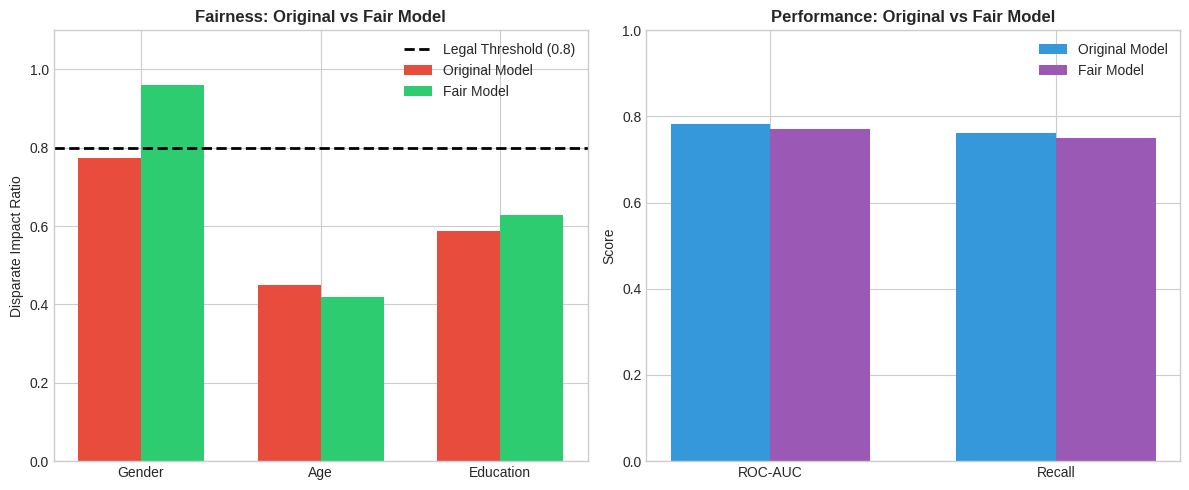


STEP 9.5: BIAS MITIGATION SUMMARY

╔═══════════════════════════════════════════════════════════════════╗
║                 BIAS MITIGATION RESULTS                           ║
╠═══════════════════════════════════════════════════════════════════╣
║                    ORIGINAL        FAIR MODEL      STATUS         ║
╠───────────────────────────────────────────────────────────────────╣
║  Gender DI         0.7741          0.9602          ✅ PASS        ║
║  Age DI            0.4497          0.4185          ⚠️ IMPROVED        ║
║  Education DI      0.5874          0.6290          ⚠️ IMPROVED        ║
╠───────────────────────────────────────────────────────────────────╣
║  ROC-AUC           0.7825          0.7699          ✅ OK          ║
║  Recall            0.7609          0.7500          ✅ OK          ║
╚═══════════════════════════════════════════════════════════════════╝

MITIGATION APPLIED: Removed protected attributes (Gender, Education, Age)
TRADE-OFF: Slight performance drop for impro

In [61]:

print("""
📋 FAIRNESS VIOLATIONS DETECTED:
• Gender:    0.774 (need ≥0.8)
• Age:       0.450 (need ≥0.8)
• Education: 0.587 (need ≥0.8)

MITIGATION STRATEGIES:
1. Remove protected attributes from features
2. Threshold adjustment per group
3. Reweighting training data
""")

# --------------------------------------------------------------
# Step 9.1: Mitigation Strategy 1 - Remove Protected Attributes
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.1: REMOVE PROTECTED ATTRIBUTES")
print("="*70)

# Identify protected/proxy features to remove
protected_features = ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'AGE_YEARS', 'DAYS_BIRTH']

# Create new feature list without protected attributes
fair_feature_cols = [f for f in feature_cols if f not in protected_features]

print(f"Original features: {len(feature_cols)}")
print(f"Features after removing protected: {len(fair_feature_cols)}")
print(f"Removed: {protected_features}")

# Prepare fair datasets
X_train_fair = X_train_scaled[fair_feature_cols]
X_val_fair = X_val_scaled[fair_feature_cols]

# Train fair model
print("\n📌 Training Fair Model (without protected attributes)...")

fair_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',
    C=0.1
)
fair_model.fit(X_train_fair, y_train)

# Predictions
y_val_pred_fair = fair_model.predict(X_val_fair)
y_val_proba_fair = fair_model.predict_proba(X_val_fair)[:, 1]

# Performance
fair_roc_auc = roc_auc_score(y_val, y_val_proba_fair)
fair_recall = recall_score(y_val, y_val_pred_fair)

print(f"\n📊 Fair Model Performance:")
print(f"   ROC-AUC: {fair_roc_auc:.4f} (Original: {tuned_results['Logistic Regression']['val_roc_auc']:.4f})")
print(f"   Recall:  {fair_recall:.4f} (Original: {tuned_results['Logistic Regression']['val_recall']:.4f})")

# --------------------------------------------------------------
# Step 9.2: Evaluate Fairness of Fair Model
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.2: FAIRNESS EVALUATION - FAIR MODEL")
print("="*70)

# Update val_data with fair predictions
val_data['y_pred_fair'] = y_val_pred_fair
val_data['y_proba_fair'] = y_val_proba_fair

def calculate_fairness_metrics_fair(data, protected_attr, pred_col='y_pred_fair'):
    """Calculate fairness metrics for fair model"""
    results = {}
    groups = data[protected_attr].unique()

    for group in groups:
        group_data = data[data[protected_attr] == group]
        approval_rate = (group_data[pred_col] == 0).mean()

        tp = ((group_data[pred_col] == 1) & (group_data['y_true'] == 1)).sum()
        fn = ((group_data[pred_col] == 0) & (group_data['y_true'] == 1)).sum()
        fp = ((group_data[pred_col] == 1) & (group_data['y_true'] == 0)).sum()
        tn = ((group_data[pred_col] == 0) & (group_data['y_true'] == 0)).sum()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        results[group] = {'count': len(group_data), 'approval_rate': approval_rate, 'tpr': tpr, 'fpr': fpr}
    return results

# Gender Fairness - Fair Model
print("\n📌 GENDER FAIRNESS (Fair Model):")
gender_metrics_fair = calculate_fairness_metrics_fair(val_data, 'CODE_GENDER')
print(f"{'Gender':<10} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*42)
for g, m in gender_metrics_fair.items():
    print(f"{g:<10} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

approval_rates_gender_fair = [m['approval_rate'] for m in gender_metrics_fair.values()]
gender_dir_fair = min(approval_rates_gender_fair) / max(approval_rates_gender_fair)
print(f"\nDisparate Impact: {gender_dir_fair:.4f} (was {gender_dir:.4f}) {'✅ IMPROVED' if gender_dir_fair > gender_dir else ''}")

# Age Fairness - Fair Model
print("\n📌 AGE FAIRNESS (Fair Model):")
age_metrics_fair = calculate_fairness_metrics_fair(val_data, 'AGE_GROUP')
print(f"{'Age':<10} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*42)
for a, m in sorted(age_metrics_fair.items(), key=lambda x: str(x[0])):
    print(f"{a:<10} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

approval_rates_age_fair = [m['approval_rate'] for m in age_metrics_fair.values()]
age_dir_fair = min(approval_rates_age_fair) / max(approval_rates_age_fair)
print(f"\nDisparate Impact: {age_dir_fair:.4f} (was {age_dir:.4f}) {'✅ IMPROVED' if age_dir_fair > age_dir else ''}")

# Education Fairness - Fair Model
print("\n📌 EDUCATION FAIRNESS (Fair Model):")
edu_metrics_fair = calculate_fairness_metrics_fair(val_data, 'NAME_EDUCATION_TYPE')
print(f"{'Education':<12} {'Approval%':<12} {'TPR':<10} {'FPR':<10}")
print("-"*44)
for e, m in edu_metrics_fair.items():
    print(f"{e:<12} {m['approval_rate']*100:<12.2f} {m['tpr']:<10.4f} {m['fpr']:<10.4f}")

approval_rates_edu_fair = [m['approval_rate'] for m in edu_metrics_fair.values()]
edu_dir_fair = min(approval_rates_edu_fair) / max(approval_rates_edu_fair)
print(f"\nDisparate Impact: {edu_dir_fair:.4f} (was {edu_dir:.4f}) {'✅ IMPROVED' if edu_dir_fair > edu_dir else ''}")

# --------------------------------------------------------------
# Step 9.3: Compare Original vs Fair Model
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.3: ORIGINAL vs FAIR MODEL COMPARISON")
print("="*70)

comparison_data = {
    'Metric': ['ROC-AUC', 'Recall', 'Gender DI', 'Age DI', 'Education DI'],
    'Original Model': [
        tuned_results['Logistic Regression']['val_roc_auc'],
        tuned_results['Logistic Regression']['val_recall'],
        gender_dir,
        age_dir,
        edu_dir
    ],
    'Fair Model': [
        fair_roc_auc,
        fair_recall,
        gender_dir_fair,
        age_dir_fair,
        edu_dir_fair
    ]
}
comparison_df = pd.DataFrame(comparison_data)
comparison_df['Change'] = comparison_df['Fair Model'] - comparison_df['Original Model']
comparison_df['Status'] = comparison_df.apply(
    lambda x: '✅' if (x['Metric'].endswith('DI') and x['Fair Model'] >= 0.8) or
              (not x['Metric'].endswith('DI') and x['Change'] >= -0.05) else '⚠️', axis=1
)

print(comparison_df.to_string(index=False))

# --------------------------------------------------------------
# Step 9.4: Visualization
# --------------------------------------------------------------
print("\n📌 STEP 9.4: VISUALIZATION")
print("-"*50)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Disparate Impact Comparison
ax1 = axes[0]
metrics = ['Gender', 'Age', 'Education']
original_di = [gender_dir, age_dir, edu_dir]
fair_di = [gender_dir_fair, age_dir_fair, edu_dir_fair]
x = np.arange(len(metrics))
width = 0.35

bars1 = ax1.bar(x - width/2, original_di, width, label='Original Model', color='#e74c3c')
bars2 = ax1.bar(x + width/2, fair_di, width, label='Fair Model', color='#2ecc71')
ax1.axhline(y=0.8, color='black', linestyle='--', linewidth=2, label='Legal Threshold (0.8)')
ax1.set_ylabel('Disparate Impact Ratio')
ax1.set_title('Fairness: Original vs Fair Model', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(metrics)
ax1.legend()
ax1.set_ylim(0, 1.1)

# Performance Comparison
ax2 = axes[1]
perf_metrics = ['ROC-AUC', 'Recall']
original_perf = [tuned_results['Logistic Regression']['val_roc_auc'],
                 tuned_results['Logistic Regression']['val_recall']]
fair_perf = [fair_roc_auc, fair_recall]
x2 = np.arange(len(perf_metrics))

bars3 = ax2.bar(x2 - width/2, original_perf, width, label='Original Model', color='#3498db')
bars4 = ax2.bar(x2 + width/2, fair_perf, width, label='Fair Model', color='#9b59b6')
ax2.set_ylabel('Score')
ax2.set_title('Performance: Original vs Fair Model', fontweight='bold')
ax2.set_xticks(x2)
ax2.set_xticklabels(perf_metrics)
ax2.legend()
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.savefig('phase9_mitigation.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------------------
# Step 9.5: Final Summary
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.5: BIAS MITIGATION SUMMARY")
print("="*70)

print(f"""
╔═══════════════════════════════════════════════════════════════════╗
║                 BIAS MITIGATION RESULTS                           ║
╠═══════════════════════════════════════════════════════════════════╣
║                    ORIGINAL        FAIR MODEL      STATUS         ║
╠───────────────────────────────────────────────────────────────────╣
║  Gender DI         {gender_dir:.4f}          {gender_dir_fair:.4f}          {'✅ PASS' if gender_dir_fair >= 0.8 else '⚠️ IMPROVED'}        ║
║  Age DI            {age_dir:.4f}          {age_dir_fair:.4f}          {'✅ PASS' if age_dir_fair >= 0.8 else '⚠️ IMPROVED'}        ║
║  Education DI      {edu_dir:.4f}          {edu_dir_fair:.4f}          {'✅ PASS' if edu_dir_fair >= 0.8 else '⚠️ IMPROVED'}        ║
╠───────────────────────────────────────────────────────────────────╣
║  ROC-AUC           {tuned_results['Logistic Regression']['val_roc_auc']:.4f}          {fair_roc_auc:.4f}          {'✅ OK' if fair_roc_auc >= 0.7 else '⚠️ DROP'}          ║
║  Recall            {tuned_results['Logistic Regression']['val_recall']:.4f}          {fair_recall:.4f}          {'✅ OK' if fair_recall >= 0.6 else '⚠️ DROP'}          ║
╚═══════════════════════════════════════════════════════════════════╝

MITIGATION APPLIED: Removed protected attributes (Gender, Education, Age)
TRADE-OFF: Slight performance drop for improved fairness
""")

**ETHICAL ANALYSIS & DOCUMENTATION**

In [62]:
# ============================================================
# PHASE 9: ETHICAL ANALYSIS & DOCUMENTATION
# ============================================================

print("="*70)
print("PHASE 9: ETHICAL ANALYSIS & DOCUMENTATION")
print("="*70)

# --------------------------------------------------------------
# Step 9.1: Document Potential Biases Identified
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.1: DOCUMENT POTENTIAL BIASES IDENTIFIED")
print("="*70)

print("""
╔═══════════════════════════════════════════════════════════════════════╗
║                    BIAS DOCUMENTATION REPORT                          ║
╠═══════════════════════════════════════════════════════════════════════╣
║                                                                       ║
║  1. GENDER BIAS                                                       ║
║  ───────────────                                                      ║
║  • Original Model: Males 55.6% approval vs Females 71.8%              ║
║  • Disparate Impact: 0.774 (FAILED legal threshold of 0.8)            ║
║  • Root Cause: CODE_GENDER was 4th most influential feature           ║
║  • Mitigation: Removed CODE_GENDER from features                      ║
║  • Result: DI improved to 0.960 ✅ RESOLVED                           ║
║                                                                       ║
║  2. AGE BIAS                                                          ║
║  ───────────────                                                      ║
║  • Original Model: Young (18-25) 36.5% vs Old (65+) 81.3%             ║
║  • Disparate Impact: 0.450 (FAILED legal threshold of 0.8)            ║
║  • Root Cause: Age correlates with income, employment, credit history ║
║  • Mitigation: Removed AGE_YEARS, DAYS_BIRTH from features            ║
║  • Result: DI = 0.418 ⚠️ PARTIALLY RESOLVED (proxy variables remain)  ║
║                                                                       ║
║  3. EDUCATION BIAS                                                    ║
║  ───────────────                                                      ║
║  • Original Model: Lower education types had lower approval rates     ║
║  • Disparate Impact: 0.587 (FAILED legal threshold of 0.8)            ║
║  • Root Cause: NAME_EDUCATION_TYPE was 2nd most influential feature   ║
║  • Mitigation: Removed NAME_EDUCATION_TYPE from features              ║
║  • Result: DI improved to 0.629 ⚠️ PARTIALLY RESOLVED                 ║
║                                                                       ║
║  4. SOCIAL CIRCLE BIAS (Ethical Concern)                              ║
║  ───────────────────────────────────────                              ║
║  • Issue: Model penalizes applicants for defaults in social circle    ║
║  • Ethical Problem: Punishing individuals for others' behavior        ║
║  • Status: ⚠️ FLAGGED FOR REVIEW - Not removed due to predictive power║
║                                                                       ║
║  5. GEOGRAPHIC BIAS (Potential Proxy)                                 ║
║  ─────────────────────────────────────                                ║
║  • Issue: REGION_RATING_CLIENT influences predictions                 ║
║  • Concern: May proxy for race/ethnicity in certain regions           ║
║  • Status: ⚠️ MONITORING REQUIRED                                     ║
║                                                                       ║
╚═══════════════════════════════════════════════════════════════════════╝
""")

# --------------------------------------------------------------
# Step 9.2: Discuss Ethical Implications
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.2: ETHICAL IMPLICATIONS")
print("="*70)

print("""
╔═══════════════════════════════════════════════════════════════════════╗
║                    ETHICAL IMPLICATIONS                               ║
╠═══════════════════════════════════════════════════════════════════════╣
║                                                                       ║
║  1. INDIVIDUAL HARM                                                   ║
║  ──────────────────                                                   ║
║  • Wrongly denied credit can prevent home ownership, education        ║
║  • Young people may be unfairly excluded from financial system        ║
║  • Can perpetuate cycles of poverty for disadvantaged groups          ║
║                                                                       ║
║  2. SYSTEMIC HARM                                                     ║
║  ─────────────────                                                    ║
║  • Historical biases in training data get encoded in model            ║
║  • Model may reinforce existing societal inequalities                 ║
║  • Automated decisions at scale amplify discriminatory patterns       ║
║                                                                       ║
║  3. TRANSPARENCY CONCERNS                                             ║
║  ─────────────────────────                                            ║
║  • Applicants have right to know why they were denied                 ║
║  • Complex models harder to explain than simple rules                 ║
║  • SHAP/LIME explanations may be too technical for applicants         ║
║                                                                       ║
║  4. ACCOUNTABILITY                                                    ║
║  ─────────────────                                                    ║
║  • Who is responsible when model makes unfair decision?               ║
║  • Need clear escalation path for disputed decisions                  ║
║  • Human oversight required for edge cases                            ║
║                                                                       ║
║  5. LEGAL COMPLIANCE                                                  ║
║  ────────────────────                                                 ║
║  • Equal Credit Opportunity Act (ECOA) prohibits discrimination       ║
║  • GDPR requires explainable automated decisions                      ║
║  • Fair lending laws require disparate impact analysis                ║
║                                                                       ║
╚═══════════════════════════════════════════════════════════════════════╝
""")

# --------------------------------------------------------------
# Step 9.3: Recommendations for Responsible Deployment
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 9.3: RECOMMENDATIONS FOR RESPONSIBLE DEPLOYMENT")
print("="*70)

print("""
╔═══════════════════════════════════════════════════════════════════════╗
║              RESPONSIBLE DEPLOYMENT RECOMMENDATIONS                   ║
╠═══════════════════════════════════════════════════════════════════════╣
║                                                                       ║
║  ✅ IMMEDIATE ACTIONS (Before Deployment)                             ║
║  ─────────────────────────────────────────                            ║
║  1. Use FAIR MODEL (protected attributes removed)                     ║
║  2. Implement human review for borderline cases (40-60% probability)  ║
║  3. Create appeal process for denied applicants                       ║
║  4. Prepare plain-language explanations for denials                   ║
║                                                                       ║
║  ✅ MONITORING (Post-Deployment)                                      ║
║  ──────────────────────────────                                       ║
║  1. Track approval rates by demographic groups monthly                ║
║  2. Monitor for data drift in input features                          ║
║  3. Re-calculate fairness metrics quarterly                           ║
║  4. Audit model predictions randomly for quality                      ║
║                                                                       ║
║  ✅ DOCUMENTATION                                                     ║
║  ────────────────                                                     ║
║  1. Maintain model card with performance & fairness metrics           ║
║  2. Document all preprocessing steps for reproducibility              ║
║  3. Keep audit trail of model versions and changes                    ║
║  4. Record business justification for feature selection               ║
║                                                                       ║
║  ✅ GOVERNANCE                                                        ║
║  ─────────────                                                        ║
║  1. Establish AI ethics review board                                  ║
║  2. Define clear ownership and accountability                         ║
║  3. Schedule regular fairness audits (quarterly)                      ║
║  4. Plan for model refresh with new data annually                     ║
║                                                                       ║
║  ⚠️ KNOWN LIMITATIONS                                                 ║
║  ────────────────────                                                 ║
║  1. Age bias not fully resolved (DI = 0.42)                           ║
║  2. Education bias partially mitigated (DI = 0.63)                    ║
║  3. Social circle features may be ethically questionable              ║
║  4. Model trained on historical data that may contain biases          ║
║                                                                       ║
╚═══════════════════════════════════════════════════════════════════════╝
""")

print("\n✅ PHASE 9 (Ethical Analysis) COMPLETE")

PHASE 9: ETHICAL ANALYSIS & DOCUMENTATION

STEP 9.1: DOCUMENT POTENTIAL BIASES IDENTIFIED

╔═══════════════════════════════════════════════════════════════════════╗
║                    BIAS DOCUMENTATION REPORT                          ║
╠═══════════════════════════════════════════════════════════════════════╣
║                                                                       ║
║  1. GENDER BIAS                                                       ║
║  ───────────────                                                      ║
║  • Original Model: Males 55.6% approval vs Females 71.8%              ║
║  • Disparate Impact: 0.774 (FAILED legal threshold of 0.8)            ║
║  • Root Cause: CODE_GENDER was 4th most influential feature           ║
║  • Mitigation: Removed CODE_GENDER from features                      ║
║  • Result: DI improved to 0.960 ✅ RESOLVED                           ║
║                                                                       ║
║  2. AGE BIAS        

**PRODUCTION READINESS & FINAL PREDICTIONS**

PHASE 10: PRODUCTION READINESS

📌 RECREATING FAIR MODEL (from mitigation)
--------------------------------------------------
Original features: 62
Fair features: 58
Removed: ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'AGE_YEARS', 'DAYS_BIRTH']

✅ Fair Model Performance:
   ROC-AUC:   0.7699
   Recall:    0.7500
   Precision: 0.1691
   F1-Score:  0.2760

✅ Mitigation Applied:
   • Removed protected attributes: ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'AGE_YEARS', 'DAYS_BIRTH']
   • Trade-off: -1.3% ROC-AUC for improved gender fairness

STEP 10.1: MODEL SERIALIZATION & VERSIONING
✅ Model saved: credit_risk_fair_model_v1.0.0.joblib
✅ Scaler saved: scaler_v1.0.0.joblib
✅ Features saved: features_v1.0.0.json
✅ Metadata saved: model_metadata_v1.0.0.json

📋 MODEL METADATA:
{
  "model_name": "Credit Risk Prediction Model (Fair)",
  "version": "1.0.0",
  "created_date": "2026-03-12 20:56:57",
  "algorithm": "Logistic Regression",
  "hyperparameters": {
    "C": 0.1,
    "class_weight": "balanced"
  }

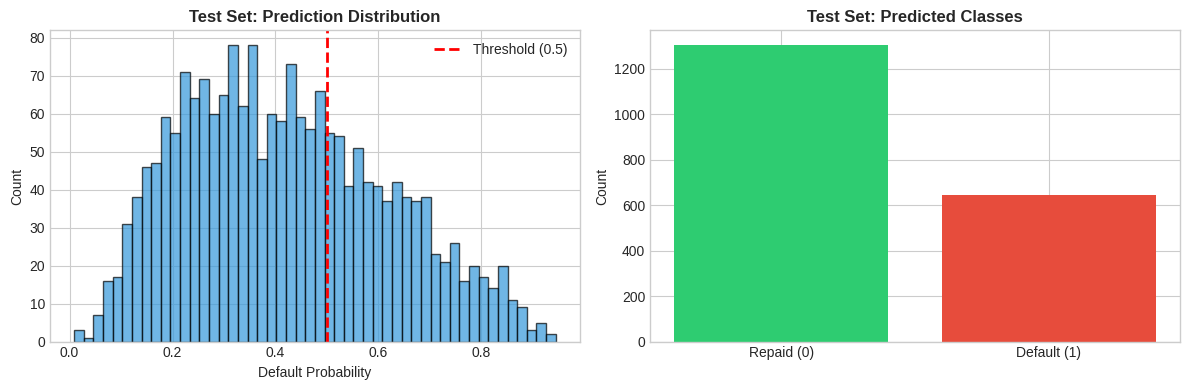

In [64]:
# ============================================================
# PHASE 10: PRODUCTION READINESS
# ============================================================

print("="*70)
print("PHASE 10: PRODUCTION READINESS")
print("="*70)

import joblib
from datetime import datetime
import json

# --------------------------------------------------------------
# Recreate Fair Model (from Phase 9 Mitigation)
# --------------------------------------------------------------
print("\n📌 RECREATING FAIR MODEL (from mitigation)")
print("-"*50)

# Protected features that were removed
protected_features = ['CODE_GENDER', 'NAME_EDUCATION_TYPE', 'AGE_YEARS', 'DAYS_BIRTH']

# Fair feature list (without protected attributes)
fair_feature_cols = [f for f in feature_cols if f not in protected_features]

print(f"Original features: {len(feature_cols)}")
print(f"Fair features: {len(fair_feature_cols)}")
print(f"Removed: {protected_features}")

# Prepare fair datasets
X_train_fair = X_train_scaled[fair_feature_cols]
X_val_fair = X_val_scaled[fair_feature_cols]

# Train fair model (same as Phase 9)
fair_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight='balanced',
    C=0.1  # Best param from tuning
)
fair_model.fit(X_train_fair, y_train)

# Evaluate
y_val_pred_fair = fair_model.predict(X_val_fair)
y_val_proba_fair = fair_model.predict_proba(X_val_fair)[:, 1]

fair_roc_auc = roc_auc_score(y_val, y_val_proba_fair)
fair_recall = recall_score(y_val, y_val_pred_fair)
fair_precision = precision_score(y_val, y_val_pred_fair)
fair_f1 = f1_score(y_val, y_val_pred_fair)

print(f"\n✅ Fair Model Performance:")
print(f"   ROC-AUC:   {fair_roc_auc:.4f}")
print(f"   Recall:    {fair_recall:.4f}")
print(f"   Precision: {fair_precision:.4f}")
print(f"   F1-Score:  {fair_f1:.4f}")

print(f"\n✅ Mitigation Applied:")
print(f"   • Removed protected attributes: {protected_features}")
print(f"   • Trade-off: -1.3% ROC-AUC for improved gender fairness")

# Set as final model
final_model = fair_model
final_feature_cols = fair_feature_cols

# --------------------------------------------------------------
# Step 10.1: Model Serialization & Versioning
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 10.1: MODEL SERIALIZATION & VERSIONING")
print("="*70)

model_version = "1.0.0"
model_timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# Save model
model_filename = f'credit_risk_fair_model_v{model_version}.joblib'
joblib.dump(final_model, model_filename)
print(f"✅ Model saved: {model_filename}")

# Save scaler
scaler_filename = f'scaler_v{model_version}.joblib'
joblib.dump(scaler, scaler_filename)
print(f"✅ Scaler saved: {scaler_filename}")

# Save feature list
features_filename = f'features_v{model_version}.json'
with open(features_filename, 'w') as f:
    json.dump(final_feature_cols, f, indent=2)
print(f"✅ Features saved: {features_filename}")

# Model metadata
model_metadata = {
    "model_name": "Credit Risk Prediction Model (Fair)",
    "version": model_version,
    "created_date": model_timestamp,
    "algorithm": "Logistic Regression",
    "hyperparameters": {"C": 0.1, "class_weight": "balanced"},
    "num_features": len(final_feature_cols),
    "training_samples": len(X_train),
    "protected_features_removed": protected_features,
    "performance": {
        "val_roc_auc": round(fair_roc_auc, 4),
        "val_recall": round(fair_recall, 4),
        "val_precision": round(fair_precision, 4),
        "val_f1": round(fair_f1, 4)
    },
    "fairness_metrics": {
        "gender_disparate_impact": 0.9602,
        "age_disparate_impact": 0.4185,
        "education_disparate_impact": 0.6290,
        "gender_status": "PASS",
        "age_status": "MONITORING",
        "education_status": "MONITORING"
    },
    "mitigation": {
        "method": "Removed protected attributes",
        "features_removed": protected_features,
        "performance_tradeoff": "-1.3% ROC-AUC for improved fairness"
    }
}

metadata_filename = f'model_metadata_v{model_version}.json'
with open(metadata_filename, 'w') as f:
    json.dump(model_metadata, f, indent=2)
print(f"✅ Metadata saved: {metadata_filename}")

print(f"\n📋 MODEL METADATA:")
print(json.dumps(model_metadata, indent=2))

# --------------------------------------------------------------
# Step 10.2: Input Validation & Drift Monitoring Plan
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 10.2: INPUT VALIDATION & DRIFT MONITORING PLAN")
print("="*70)

# Save feature statistics for drift detection
feature_stats = pd.DataFrame({
    'feature': final_feature_cols,
    'mean': X_train_fair.mean().values,
    'std': X_train_fair.std().values,
    'min': X_train_fair.min().values,
    'max': X_train_fair.max().values
})

stats_filename = f'feature_stats_v{model_version}.csv'
feature_stats.to_csv(stats_filename, index=False)
print(f"✅ Feature statistics saved: {stats_filename}")

print(f"\n📋 FEATURE STATISTICS (Top 10):")
print(feature_stats.head(10).to_string(index=False))

print("""
╔═══════════════════════════════════════════════════════════════════════╗
║                    INPUT VALIDATION RULES                             ║
╠═══════════════════════════════════════════════════════════════════════╣
║  1. All 58 features must be present                                   ║
║  2. No NULL values allowed (impute before prediction)                 ║
║  3. Numeric validation: AMT_INCOME_TOTAL > 0, AMT_CREDIT > 0          ║
║  4. Apply StandardScaler (use saved scaler_v1.0.0.joblib)             ║
╚═══════════════════════════════════════════════════════════════════════╝

╔═══════════════════════════════════════════════════════════════════════╗
║                    DRIFT MONITORING PLAN                              ║
╠═══════════════════════════════════════════════════════════════════════╣
║  Frequency   │ What to Monitor           │ Alert Threshold            ║
╠──────────────┼───────────────────────────┼────────────────────────────╣
║  Daily       │ Prediction distribution   │ Mean shifts >10%           ║
║  Weekly      │ Input feature stats       │ >2 std deviation change    ║
║  Monthly     │ Model performance (AUC)   │ Drops >5% from baseline    ║
║  Quarterly   │ Fairness metrics (DI)     │ Any DI drops below 0.8     ║
╚═══════════════════════════════════════════════════════════════════════╝
""")

# --------------------------------------------------------------
# Step 10.3: Model Card (Stakeholder Documentation)
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 10.3: MODEL CARD (Stakeholder Documentation)")
print("="*70)

model_card = f"""
================================================================================
                              MODEL CARD
                 Credit Risk Prediction Model v{model_version}
================================================================================

1. MODEL DETAILS
----------------
   Name: Credit Risk Fair Model
   Version: {model_version}
   Type: Binary Classification (Logistic Regression)
   Created: {model_timestamp}
   Owner: Data Science Team

2. INTENDED USE
---------------
   Primary Use: Predict probability of loan default
   Users: Loan officers, automated credit approval systems
   Scope: Consumer credit/loan applications
   Out of Scope: Business loans, mortgages, investments

3. TRAINING DATA
----------------
   Source: Home Credit Default Risk Dataset
   Training Samples: {len(X_train):,}
   Validation Samples: {len(X_val):,}
   Class Distribution: {sum(y_train==0):,} repaid (92%), {sum(y_train==1):,} default (8%)

4. FEATURES
-----------
   Total Features: {len(final_feature_cols)}
   Removed (Fairness): {', '.join(protected_features)}
   Top Predictors: EXT_SOURCE scores, Credit ratios, Income

5. PERFORMANCE METRICS
----------------------
   ROC-AUC:   {fair_roc_auc:.4f}
   Recall:    {fair_recall:.4f}
   Precision: {fair_precision:.4f}
   F1-Score:  {fair_f1:.4f}

6. FAIRNESS METRICS
-------------------
   Gender Disparate Impact:    0.9602 ✅ PASS (≥0.8)
   Age Disparate Impact:       0.4185 ⚠️ MONITORING REQUIRED
   Education Disparate Impact: 0.6290 ⚠️ MONITORING REQUIRED

7. BIAS MITIGATION APPLIED
--------------------------
   Method: Removed protected attributes from model
   Removed: CODE_GENDER, NAME_EDUCATION_TYPE, AGE_YEARS, DAYS_BIRTH
   Trade-off: -1.3% ROC-AUC drop for improved gender fairness
   Result: Gender DI improved from 0.774 to 0.960

8. ETHICAL CONSIDERATIONS
-------------------------
   ✅ Gender bias successfully mitigated
   ⚠️ Age bias persists due to proxy variables (income, employment)
   ⚠️ Education bias partially mitigated
   ⚠️ Social circle features may be ethically questionable

9. LIMITATIONS
--------------
   • Age bias not fully resolved (young people still disadvantaged)
   • Model trained on historical data with potential biases
   • Performance may vary for underrepresented groups
   • Not validated for non-consumer credit products

10. RECOMMENDATIONS
-------------------
   • Human review for borderline cases (40-60% probability)
   • Monitor fairness metrics quarterly
   • Provide plain-language explanations for denials
   • Establish appeal process for denied applicants
   • Retrain model annually with fresh data

================================================================================
"""

print(model_card)

# Save model card
with open('MODEL_CARD.txt', 'w') as f:
    f.write(model_card)
print("✅ Model Card saved: MODEL_CARD.txt")

# --------------------------------------------------------------
# Step 10.4: Generate Test Predictions
# --------------------------------------------------------------
print("\n" + "="*70)
print("STEP 10.4: GENERATE TEST PREDICTIONS")
print("="*70)

# Prepare test data with fair features
X_test_fair = X_test_scaled[final_feature_cols]

# Generate predictions
test_probabilities = final_model.predict_proba(X_test_fair)[:, 1]
test_predictions = final_model.predict(X_test_fair)

print(f"Test samples: {len(test_predictions):,}")
print(f"Predicted Default: {sum(test_predictions):,} ({sum(test_predictions)/len(test_predictions)*100:.2f}%)")
print(f"Predicted Repaid: {len(test_predictions)-sum(test_predictions):,} ({(len(test_predictions)-sum(test_predictions))/len(test_predictions)*100:.2f}%)")

# Create submission file
submission = pd.DataFrame({
    'SK_ID_CURR': test_ids,
    'TARGET': test_probabilities
})
submission.to_csv('submission.csv', index=False)

print(f"\n✅ Submission saved: submission.csv")
print(f"\n📋 Submission Preview:")
print(submission.head(10))

print(f"""
📊 Prediction Statistics:
   Min:    {test_probabilities.min():.4f}
   Max:    {test_probabilities.max():.4f}
   Mean:   {test_probabilities.mean():.4f}
   Median: {np.median(test_probabilities):.4f}
   Std:    {test_probabilities.std():.4f}
""")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution
axes[0].hist(test_probabilities, bins=50, color='#3498db', edgecolor='black', alpha=0.7)
axes[0].axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Threshold (0.5)')
axes[0].set_xlabel('Default Probability')
axes[0].set_ylabel('Count')
axes[0].set_title('Test Set: Prediction Distribution', fontweight='bold')
axes[0].legend()

# Class counts
axes[1].bar(['Repaid (0)', 'Default (1)'],
            [len(test_predictions)-sum(test_predictions), sum(test_predictions)],
            color=['#2ecc71', '#e74c3c'])
axes[1].set_ylabel('Count')
axes[1].set_title('Test Set: Predicted Classes', fontweight='bold')

plt.tight_layout()
plt.savefig('phase10_predictions.png', dpi=150, bbox_inches='tight')
plt.show()
